# ENADE 2023 — resultados validados e revisão da auditoria (TASK 13)

Consulta de resultados existentes, sem repetir preparação ou análises. Os notebooks 01–04 são estruturas iniciais incompletas e não integram o pipeline obrigatório. Para reconstruir as bases ou aplicar a revisão, use os scripts e a ordem descritos no README.

O recorte permanece: grupo 6411, categorias privadas 4/5/8, presencial 1, 70 IES, 79 cursos, 1.418 inscritos e 1.203 notas utilizáveis. FG e CE pertencem ao mesmo registro do arq3. As cinco marginais socioeconômicas ficam separadas; não existe pareamento individual entre arquivos. Notas ausentes/suprimidas não recebem zero.

In [1]:
from pathlib import Path
import json
import sys
import pandas as pd
from IPython.display import Image, display
ROOT=Path.cwd()
if ROOT.name=='notebooks': ROOT=ROOT.parent
sys.path.insert(0,str(ROOT/'src'))
T=ROOT/'resultados/tabelas'
def tabela(nome): return pd.read_csv(T/(nome+'_2023.csv'),sep=';')
validacao=json.loads((T/'validacao_aprofundamento_2023.json').read_text(encoding='utf-8'))
print('Python:',sys.executable)
print('Leitura de resultados já calculados; nenhuma análise reexecutada.')

Python: C:\trabCDados\projeto-enade\.venv\Scripts\python.exe
Leitura de resultados já calculados; nenhuma análise reexecutada.


## Participação, notas e referência institucional
As notas são descrições dos resultados publicados. Grupos institucionais incluem a UNIFOR e se sobrepõem; “demais privadas” a exclui. A UNIFOR tem média geral 41,656 contra 42,440 nas sem fins lucrativos; CE 39,600 contra 38,989. Isso não demonstra superioridade geral. DP amostral e médias por curso usam os denominadores registrados.

In [2]:
display(tabela('indicadores_participacao').round(3))
display(tabela('componentes_aprofundados').round(3))
display(tabela('diferencas_componentes').round(3))

,grupo,instituicoes,cursos,cursos_com_notas,cursos_n10,inscritos,presentes,presencas_validas_oficiais,ausentes,suprimidos,outros,n_validas,taxa_participacao_pct,taxa_ausencia_pct,taxa_notas_publicadas_pct
0,UNIFOR,1,1,1,1,30,25,25,5,0,0,25,83.333,16.667,83.333
1,privado_presencial,70,79,71,47,1418,1209,1209,208,6,1,1203,85.261,14.669,84.838
2,sem_fins_lucrativos,36,39,34,24,755,680,680,74,4,1,676,90.066,9.801,89.536
3,universidades_privadas,20,29,28,21,601,522,522,79,1,0,521,86.855,13.145,86.689
4,privado_sem_unifor,69,78,70,46,1388,1184,1184,203,6,1,1178,85.303,14.625,84.870


,grupo,variavel,n,media,mediana,dp_amostral,q1,q3
0,UNIFOR,NT_GER,25,41.656,41.20,9.301,34.400,48.500
1,UNIFOR,NT_FG,25,47.776,50.60,12.374,38.600,56.600
2,UNIFOR,NT_CE,25,39.600,38.00,10.721,32.000,47.000
3,UNIFOR,NT_OBJ_FG,25,57.344,55.60,15.629,44.400,66.700
4,UNIFOR,NT_DIS_FG,25,29.996,30.90,25.219,0.000,48.000
5,UNIFOR,NT_OBJ_CE,25,42.012,41.70,11.403,33.300,50.000
6,UNIFOR,NT_DIS_CE,25,17.800,20.00,14.796,0.000,30.000
7,privado_presencial,NT_GER,1203,39.326,38.60,11.985,30.500,47.200
8,privado_presencial,NT_FG,1203,51.550,51.20,15.946,40.900,62.450
9,privado_presencial,NT_CE,1203,35.234,33.80,13.496,26.300,44.200


,grupo_referencia,variavel,n_unifor,n_referencia,media_unifor,media_referencia,diferenca_pontos
0,privado_presencial,NT_GER,25,1203,41.656,39.326,2.330
1,privado_presencial,NT_FG,25,1203,47.776,51.550,-3.774
2,privado_presencial,NT_CE,25,1203,39.600,35.234,4.366
3,privado_presencial,NT_OBJ_FG,25,1203,57.344,55.239,2.105
4,privado_presencial,NT_DIS_FG,25,1203,29.996,44.695,-14.699
5,privado_presencial,NT_OBJ_CE,25,1203,42.012,37.483,4.529
6,privado_presencial,NT_DIS_CE,25,1203,17.800,14.904,2.896
7,sem_fins_lucrativos,NT_GER,25,676,41.656,42.440,-0.784
8,sem_fins_lucrativos,NT_FG,25,676,47.776,52.737,-4.961
9,sem_fins_lucrativos,NT_CE,25,676,39.600,38.989,0.611


## FG discursiva: brancos versus respostas com resultado válido
A FG discursiva contém uma única questão. `TP_SFG_D1=333` identifica branco; zero, isoladamente, não identifica branco. Código 555 significa resultado válido e pode ter nota zero.

UNIFOR: 8/25 brancos (32,0%), média geral da questão 30,00; entre 17 respostas válidas, 44,11. Demais privadas: 70/1.178 brancos (5,9%), média 45,01; entre 1.098 respostas válidas, 48,26. Excluir apenas brancos deixa 1.108 casos e média 47,85 no referencial, pois ainda inclui seis respostas nulas (335) e quatro fora da temática (336).

A maior frequência de brancos acentua a diferença agregada; não se presumem motivos dos brancos, dificuldade de escrita ou falta de conhecimento. As médias condicionais descrevem grupos selecionados, sem causalidade. Valores publicados de códigos 335/336 são preservados, inclusive notas positivas em 336.

In [3]:
display(tabela('fg_discursiva_respostas').round(4))

,grupo,n_total,n_brancos,percentual_brancos,n_nulos,n_fora_tema,n_sem_brancos,n_respostas_validas,media_todos,media_sem_brancos,media_respostas_validas
0,UNIFOR,25,8,32.0000,0,0,17,17,29.9960,44.1118,44.1118
1,privado_presencial,1203,78,6.4838,6,4,1125,1115,44.6951,47.7940,48.1921
2,sem_fins_lucrativos,676,46,6.8047,4,2,630,624,46.5414,49.9397,50.3974
3,universidades_privadas,521,38,7.2937,4,2,483,477,43.6470,47.0810,47.6543
4,privado_sem_unifor,1178,70,5.9423,6,4,1108,1098,45.0070,47.8505,48.2553


## Correlação FG–CE
Pearson no próprio arq3, com pares completos: 25 na UNIFOR e 1.178 nas demais privadas. Não se testou diferença entre os coeficientes. Associação não implica causalidade. Os pesos oficiais da prova permanecem FG 65/35 e CE 90/10, conforme a NT 12/2024 citada no relatório; não são recalculadas notas oficiais.

In [4]:
display(tabela('correlacoes_fg_ce').round(4))

,grupo,metodo,n_pares,r_fg_ce,nivel
0,UNIFOR,Pearson,25,0.2508,individual_mesmo_arq3
1,privado_presencial,Pearson,1203,0.3132,individual_mesmo_arq3
2,sem_fins_lucrativos,Pearson,676,0.2994,individual_mesmo_arq3
3,universidades_privadas,Pearson,521,0.2910,individual_mesmo_arq3
4,privado_sem_unifor,Pearson,1178,0.3162,individual_mesmo_arq3


## Questões objetivas: extremos exploratórios
Acertos, escolhas e gabaritos são conferidos dentro do mesmo registro. Há nove itens FG e 24 CE válidos; Q17/18/19/25/34 CE são excluídas, sem percentual. FG Q3/Q4 e CE Q23/Q28 foram selecionadas após examinar todos os itens por serem os extremos positivo/negativo de cada componente. Não são fragilidades comprovadas, sem testes múltiplos ou atribuição de competências. Uma resposta na UNIFOR equivale a quatro pontos percentuais.

In [5]:
it=tabela('acertos_itens')
display(it.round(3))
dif=it.pivot(index=['componente','questao_caderno'],columns='grupo',values='percentual_acerto')
dif['diferenca_pp']=dif.UNIFOR-dif.privado_sem_unifor
display(dif[['UNIFOR','privado_sem_unifor','diferenca_pp']].round(3))

,grupo,componente,posicao_vetor,questao_caderno,gabarito_final,situacao,n_base_notas,n_respostas_validas,acertos,erros,excluidos,percentual_acerto
0,UNIFOR,FG,1,1,D,valido,25,25,16,9,0,64.000
1,UNIFOR,FG,2,2,D,valido,25,25,22,3,0,88.000
2,UNIFOR,FG,3,3,B,valido,25,25,18,7,0,72.000
3,UNIFOR,FG,4,4,A,valido,25,25,12,13,0,48.000
4,UNIFOR,FG,5,5,E,valido,25,25,11,14,0,44.000
...,...,...,...,...,...,...,...,...,...,...,...,...
185,privado_sem_unifor,CE,25,34,9,excluido_discriminacao,1178,0,0,0,1178,NaN
186,privado_sem_unifor,CE,26,35,E,valido,1178,1178,469,709,0,39.813
187,privado_sem_unifor,CE,27,36,C,valido,1178,1178,589,589,0,50.000
188,privado_sem_unifor,CE,28,37,C,valido,1178,1178,315,863,0,26.740


grupo                       UNIFOR  privado_sem_unifor  diferenca_pp
componente questao_caderno                                          
CE         10                 40.0              30.900         9.100
           11                 24.0              30.645        -6.645
           12                 20.0              16.978         3.022
           13                 36.0              22.071        13.929
           14                  8.0              15.705        -7.705
           15                 28.0              29.032        -1.032
           16                  4.0               5.942        -1.942
           17                  NaN                 NaN           NaN
           18                  NaN                 NaN           NaN
           19                  NaN                 NaN           NaN
           20                 48.0              42.954         5.046
           21                 52.0              42.530         9.470
           22                 40.0              40.577        -0.577
           23                 60.0              34.211        25.789
           24                 56.0              39.813        16.187
           25                  NaN                 NaN           NaN
           26                 68.0              65.110         2.890
           27                 48.0              33.531        14.469
           28                 32.0              47.623       -15.623
           29                 60.0              42.954        17.046
           30                 80.0              56.706        23.294
           31                 28.0              23.514         4.486
           32                 60.0              58.744         1.256
           33                 36.0              38.710        -2.710
           34                  NaN                 NaN           NaN
           35                 44.0              39.813         4.187
           36                 52.0              50.000         2.000
           37                 20.0              26.740        -6.740
           38                 64.0              62.479         1.521
FG         1                  64.0              63.752         0.248
           2                  88.0              81.664         6.336
           3                  72.0              61.885        10.115
           4                  48.0              57.131        -9.131
           5                  44.0              47.708        -3.708
           6                  80.0              79.966         0.034
           7                  40.0              30.390         9.610
           8                  52.0              48.557         3.443
           9                  28.0              25.637         2.363

## Perfil e associações por curso
As cinco marginais mantêm os denominadores de cada pergunta: 29 respostas e uma ausência na UNIFOR; 1.255 respostas e 133 ausências nas demais privadas. Não se relacionam essas respostas às notas individuais.

Nos 47 cursos com ao menos dez notas e dez respostas, as proporções de baixa renda e de ensino médio todo público apresentam associação negativa com a média geral: r=-0,413471 e r=-0,398259. A unidade é curso, com peso igual. Não há associação individual renda–nota, efeito causal ou atribuição exclusiva das diferenças ao perfil. Todas as correlações anteriores foram preservadas.

In [6]:
display(tabela('indicadores_socioeconomicos').round(3))
display(tabela('socioeconomico_grupos').round(3))
display(tabela('correlacoes_ecologicas').round(4))

,grupo,variavel,indicador,categorias,contagem,n_respondentes,n_ausentes,n_arquivo,percentual
0,UNIFOR,QE_I08,Renda familiar até 3 salários mínimos,A+B,2,29,1,30,6.897
1,privado_presencial,QE_I08,Renda familiar até 3 salários mínimos,A+B,287,1284,134,1418,22.352
2,sem_fins_lucrativos,QE_I08,Renda familiar até 3 salários mínimos,A+B,108,715,40,755,15.105
3,universidades_privadas,QE_I08,Renda familiar até 3 salários mínimos,A+B,125,555,46,601,22.523
4,privado_sem_unifor,QE_I08,Renda familiar até 3 salários mínimos,A+B,285,1255,133,1388,22.709
5,UNIFOR,QE_I10,Trabalho: 40 horas semanais ou mais,E,18,29,1,30,62.069
6,privado_presencial,QE_I10,Trabalho: 40 horas semanais ou mais,E,745,1284,134,1418,58.022
7,sem_fins_lucrativos,QE_I10,Trabalho: 40 horas semanais ou mais,E,414,715,40,755,57.902
8,universidades_privadas,QE_I10,Trabalho: 40 horas semanais ou mais,E,352,555,46,601,63.423
9,privado_sem_unifor,QE_I10,Trabalho: 40 horas semanais ou mais,E,727,1255,133,1388,57.928


,grupo,variavel,arquivo,categoria,rotulo,n_arquivo,n_respondentes,n_ausentes,contagem,percentual_respondentes
0,UNIFOR,QE_I08,arq14,A,"Até 1,5 salário mínimo (até R$ 1.980,00).",30,29,1,1,3.448
1,UNIFOR,QE_I08,arq14,B,"De 1,5 a 3 salários mínimos (R$ 1.980,01 a R$ ...",30,29,1,1,3.448
2,UNIFOR,QE_I08,arq14,C,"De 3 a 4,5 salários mínimos (R$ 3.960,01 a R$ ...",30,29,1,8,27.586
3,UNIFOR,QE_I08,arq14,D,"De 4,5 a 6 salários mínimos (R$ 5.940,01 a R$ ...",30,29,1,4,13.793
4,UNIFOR,QE_I08,arq14,E,"De 6 a 10 salários mínimos (R$ 7.920,01 a R$ 1...",30,29,1,5,17.241
...,...,...,...,...,...,...,...,...,...,...
145,privado_sem_unifor,QE_I17,arq23,B,Todo em escola privada (particular).,1388,1255,133,517,41.195
146,privado_sem_unifor,QE_I17,arq23,C,Todo no exterior.,1388,1255,133,0,0.000
147,privado_sem_unifor,QE_I17,arq23,D,A maior parte em escola pública.,1388,1255,133,37,2.948
148,privado_sem_unifor,QE_I17,arq23,E,A maior parte em escola privada (particular).,1388,1255,133,55,4.382


,variavel,indicador,n_cursos,metodo,r_agregado,unidade,peso,min_notas_respostas
0,QE_I08,Renda familiar até 3 salários mínimos,47,Pearson,-0.4135,curso,igual_por_curso,10
1,QE_I10,Trabalho: 40 horas semanais ou mais,47,Pearson,-0.0688,curso,igual_por_curso,10
2,QE_I04,Pai com graduação ou pós-graduação,47,Pearson,0.2911,curso,igual_por_curso,10
3,QE_I05,Mãe com graduação ou pós-graduação,47,Pearson,0.3434,curso,igual_por_curso,10
4,QE_I17,Ensino médio todo em escola pública,47,Pearson,-0.3983,curso,igual_por_curso,10


## Figuras atuais
Oito figuras com vírgula decimal, fonte única e legendas fora da área de dados. O relatório seleciona seis; partes da prova e boxplots permanecem como complementos. As imagens são lidas dos arquivos gerados, sem executar o renderer.

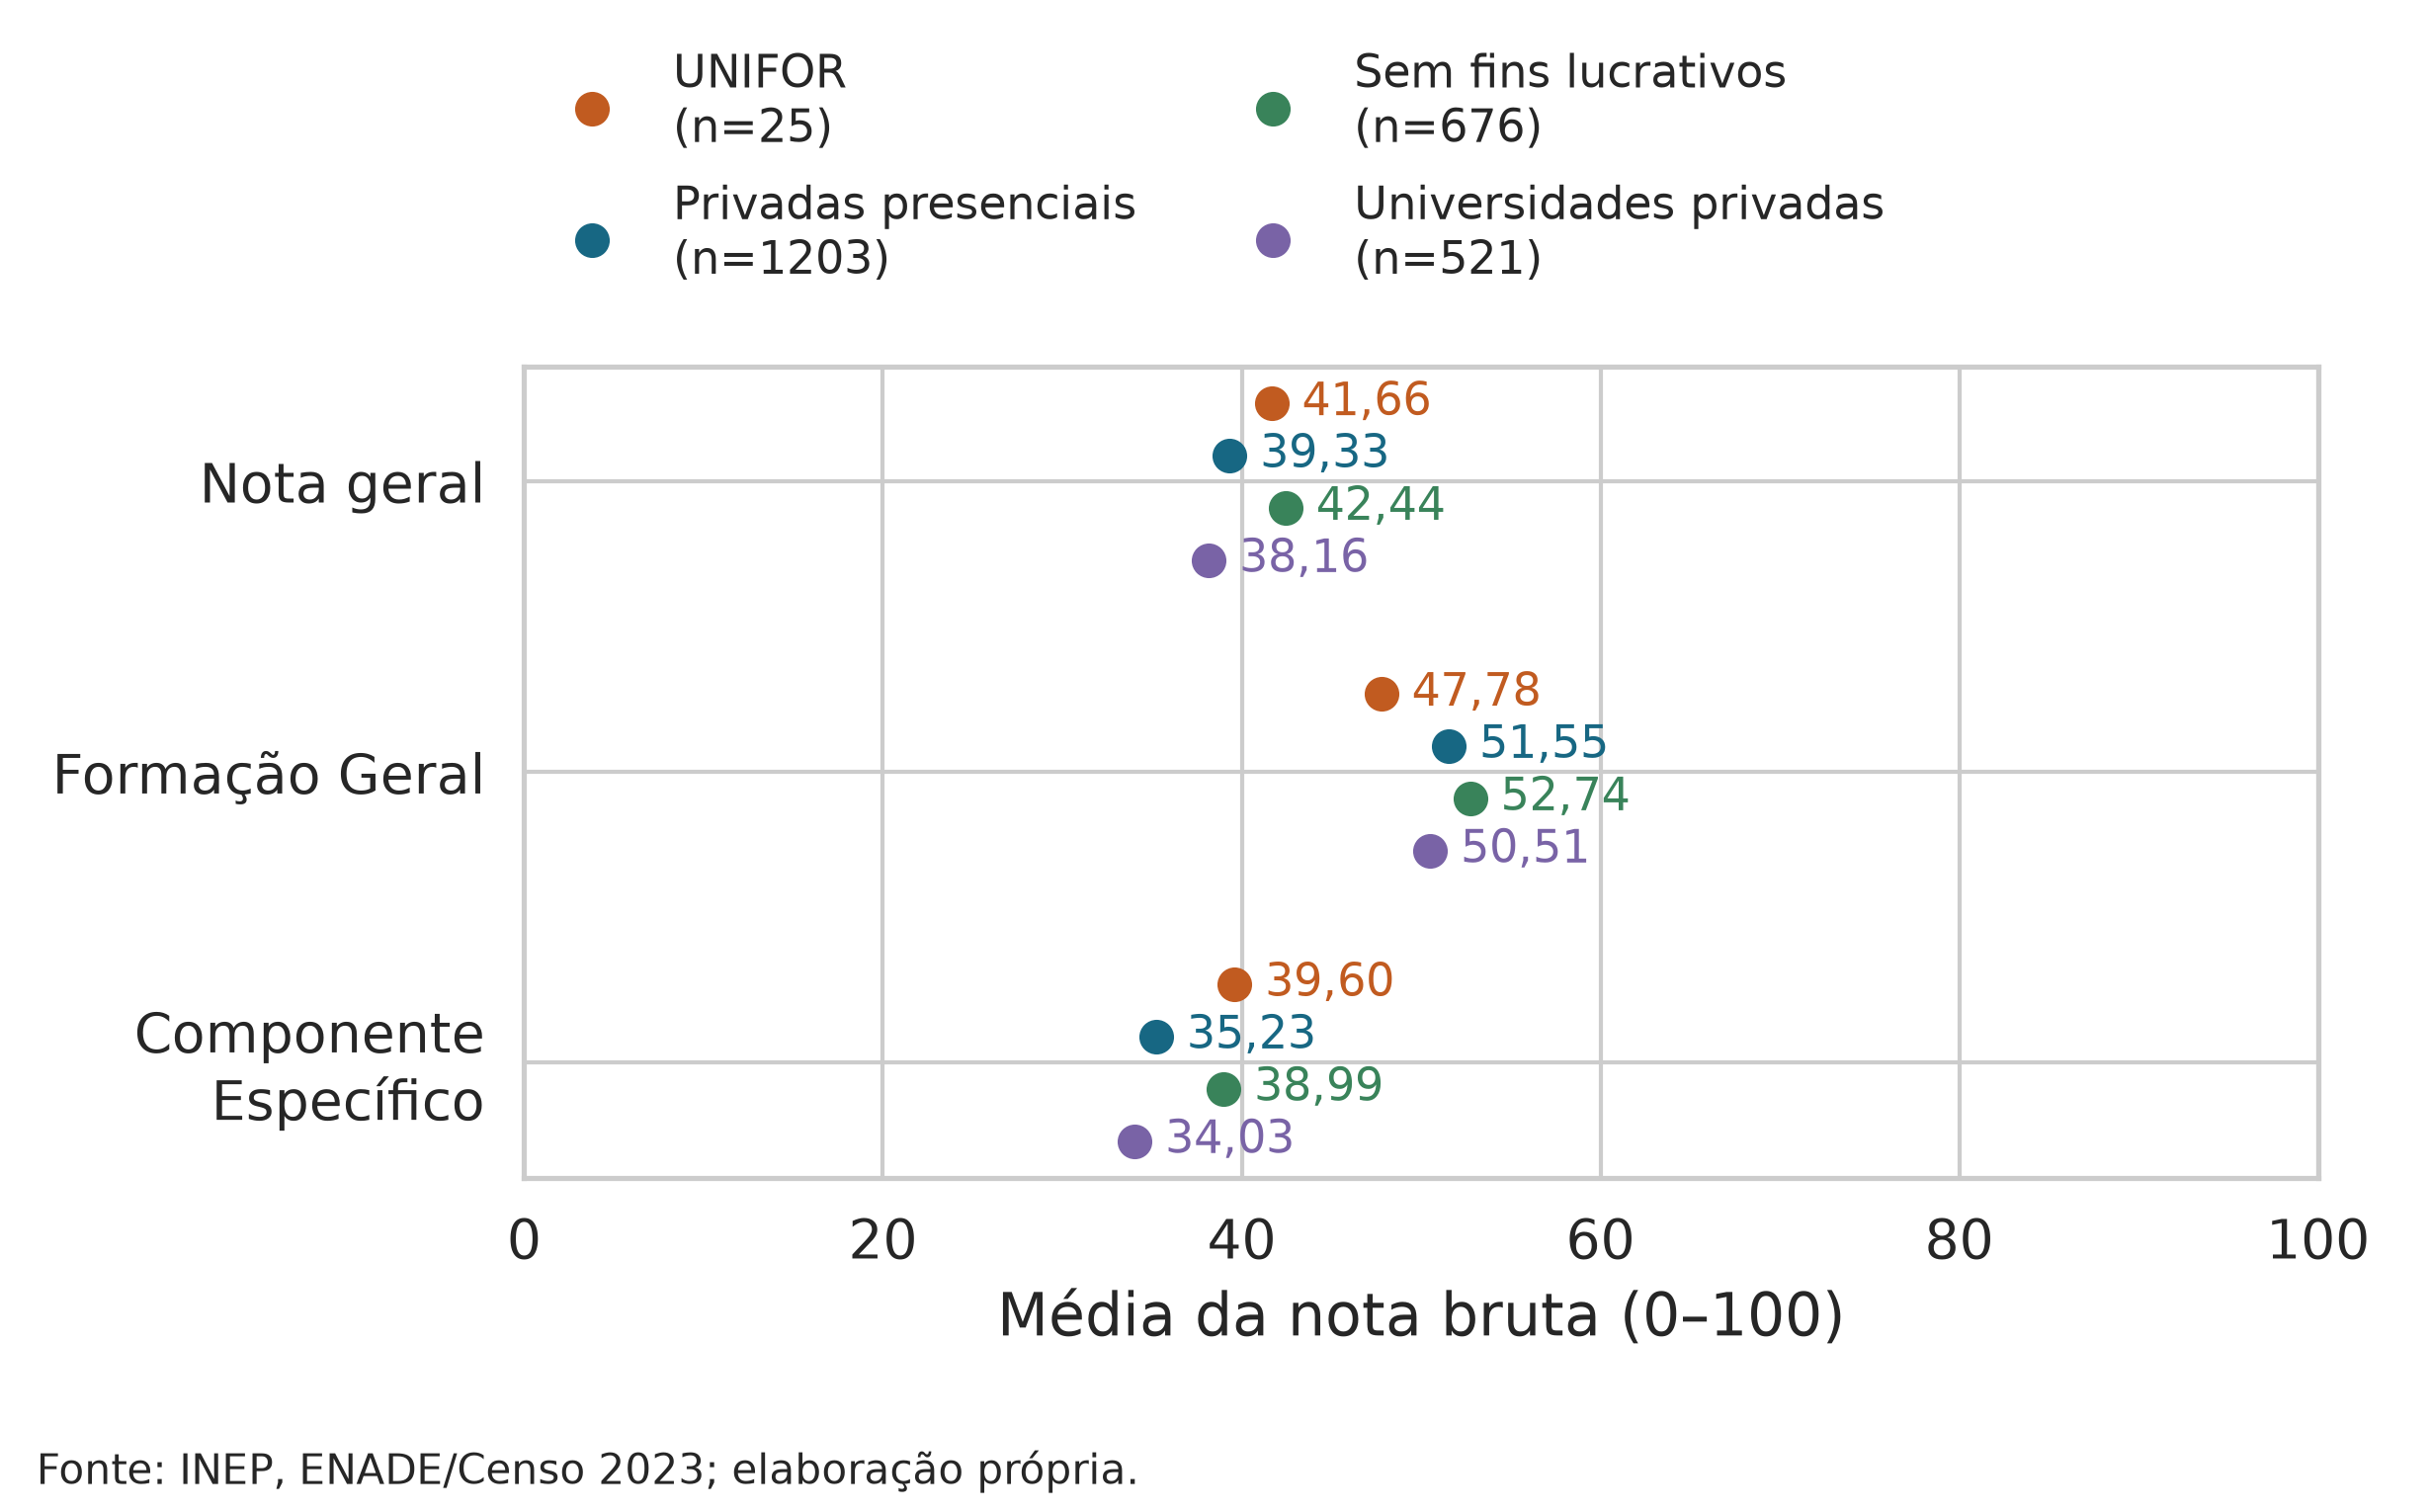

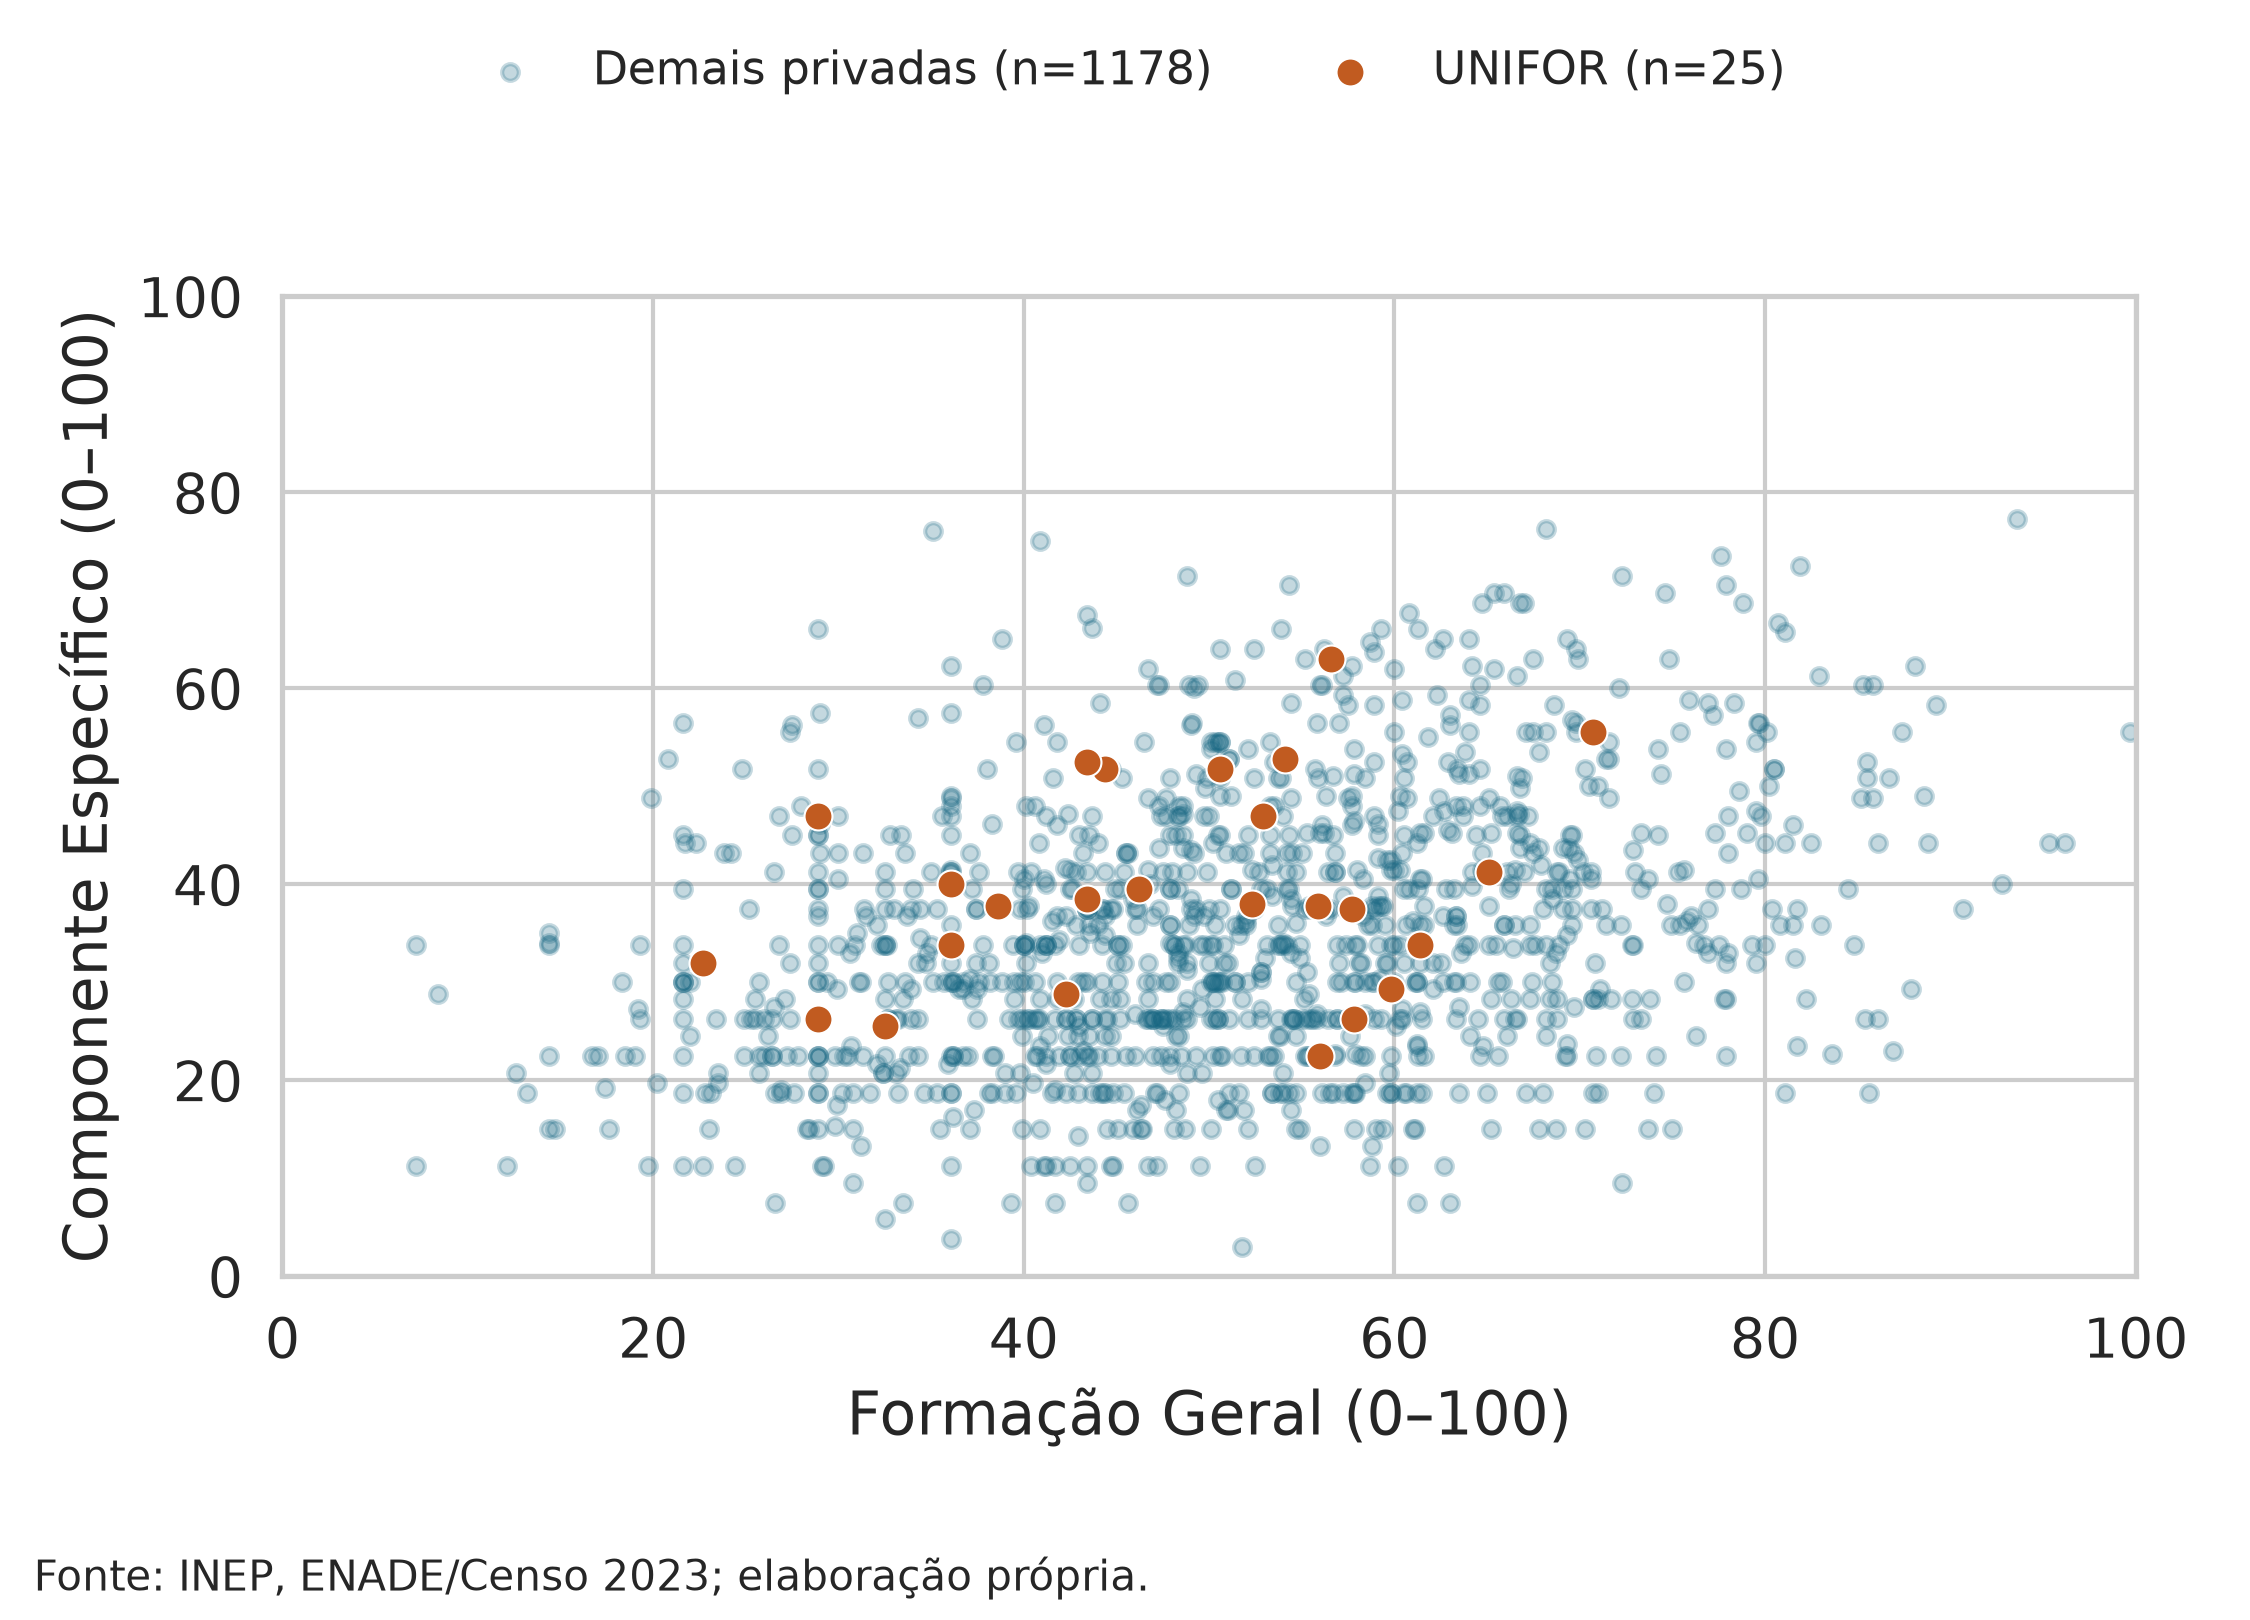

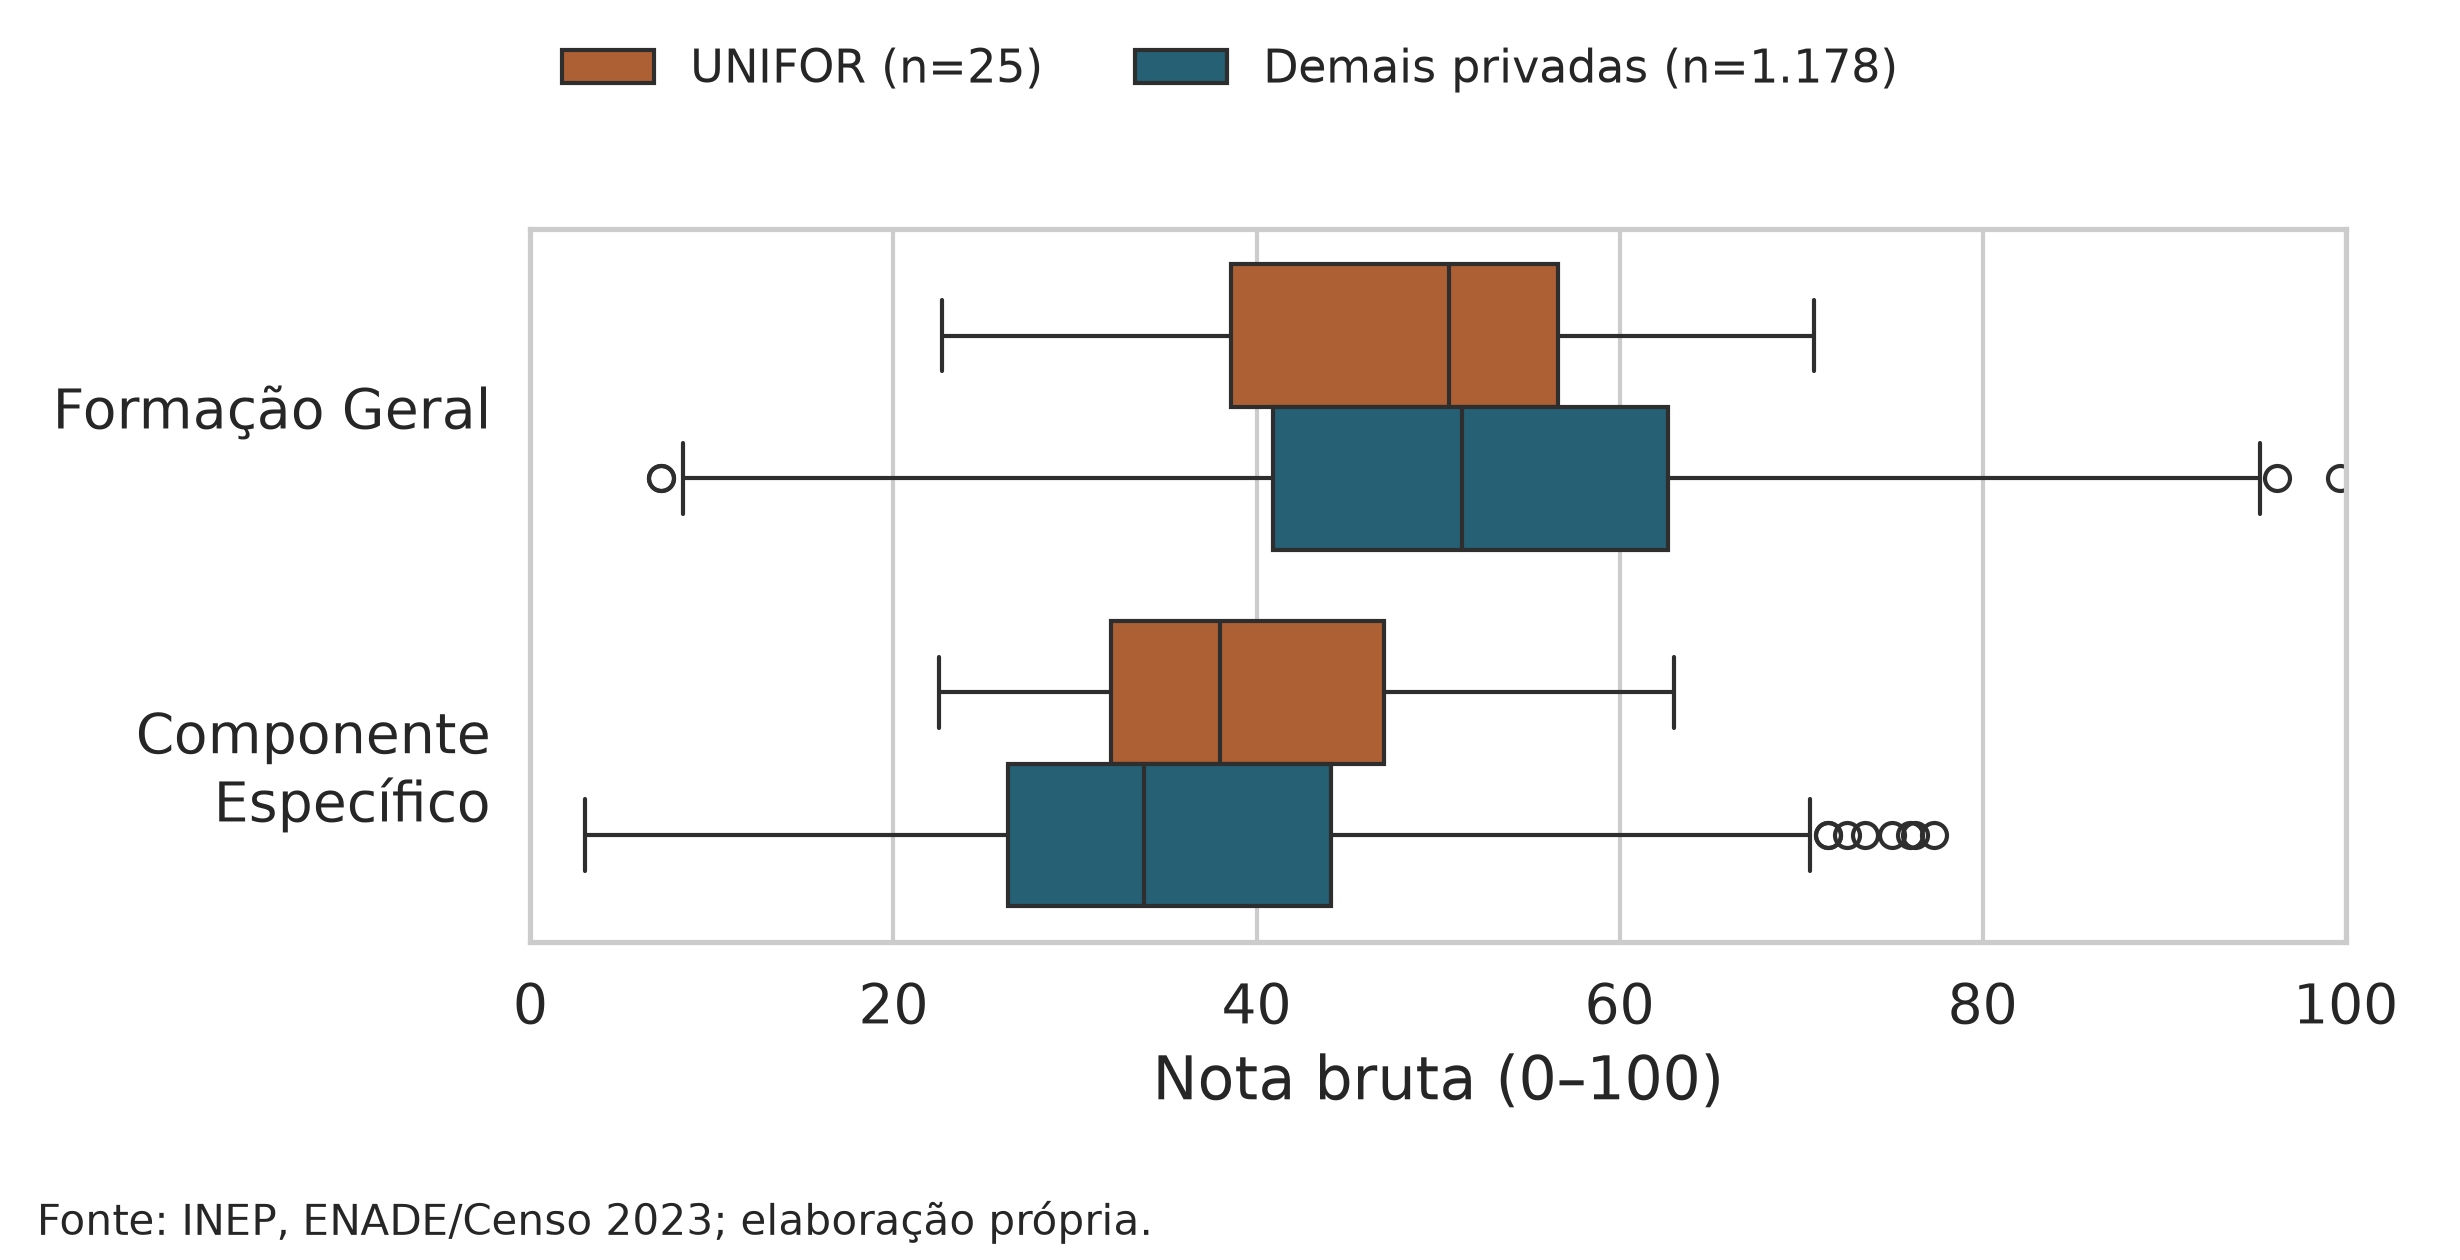

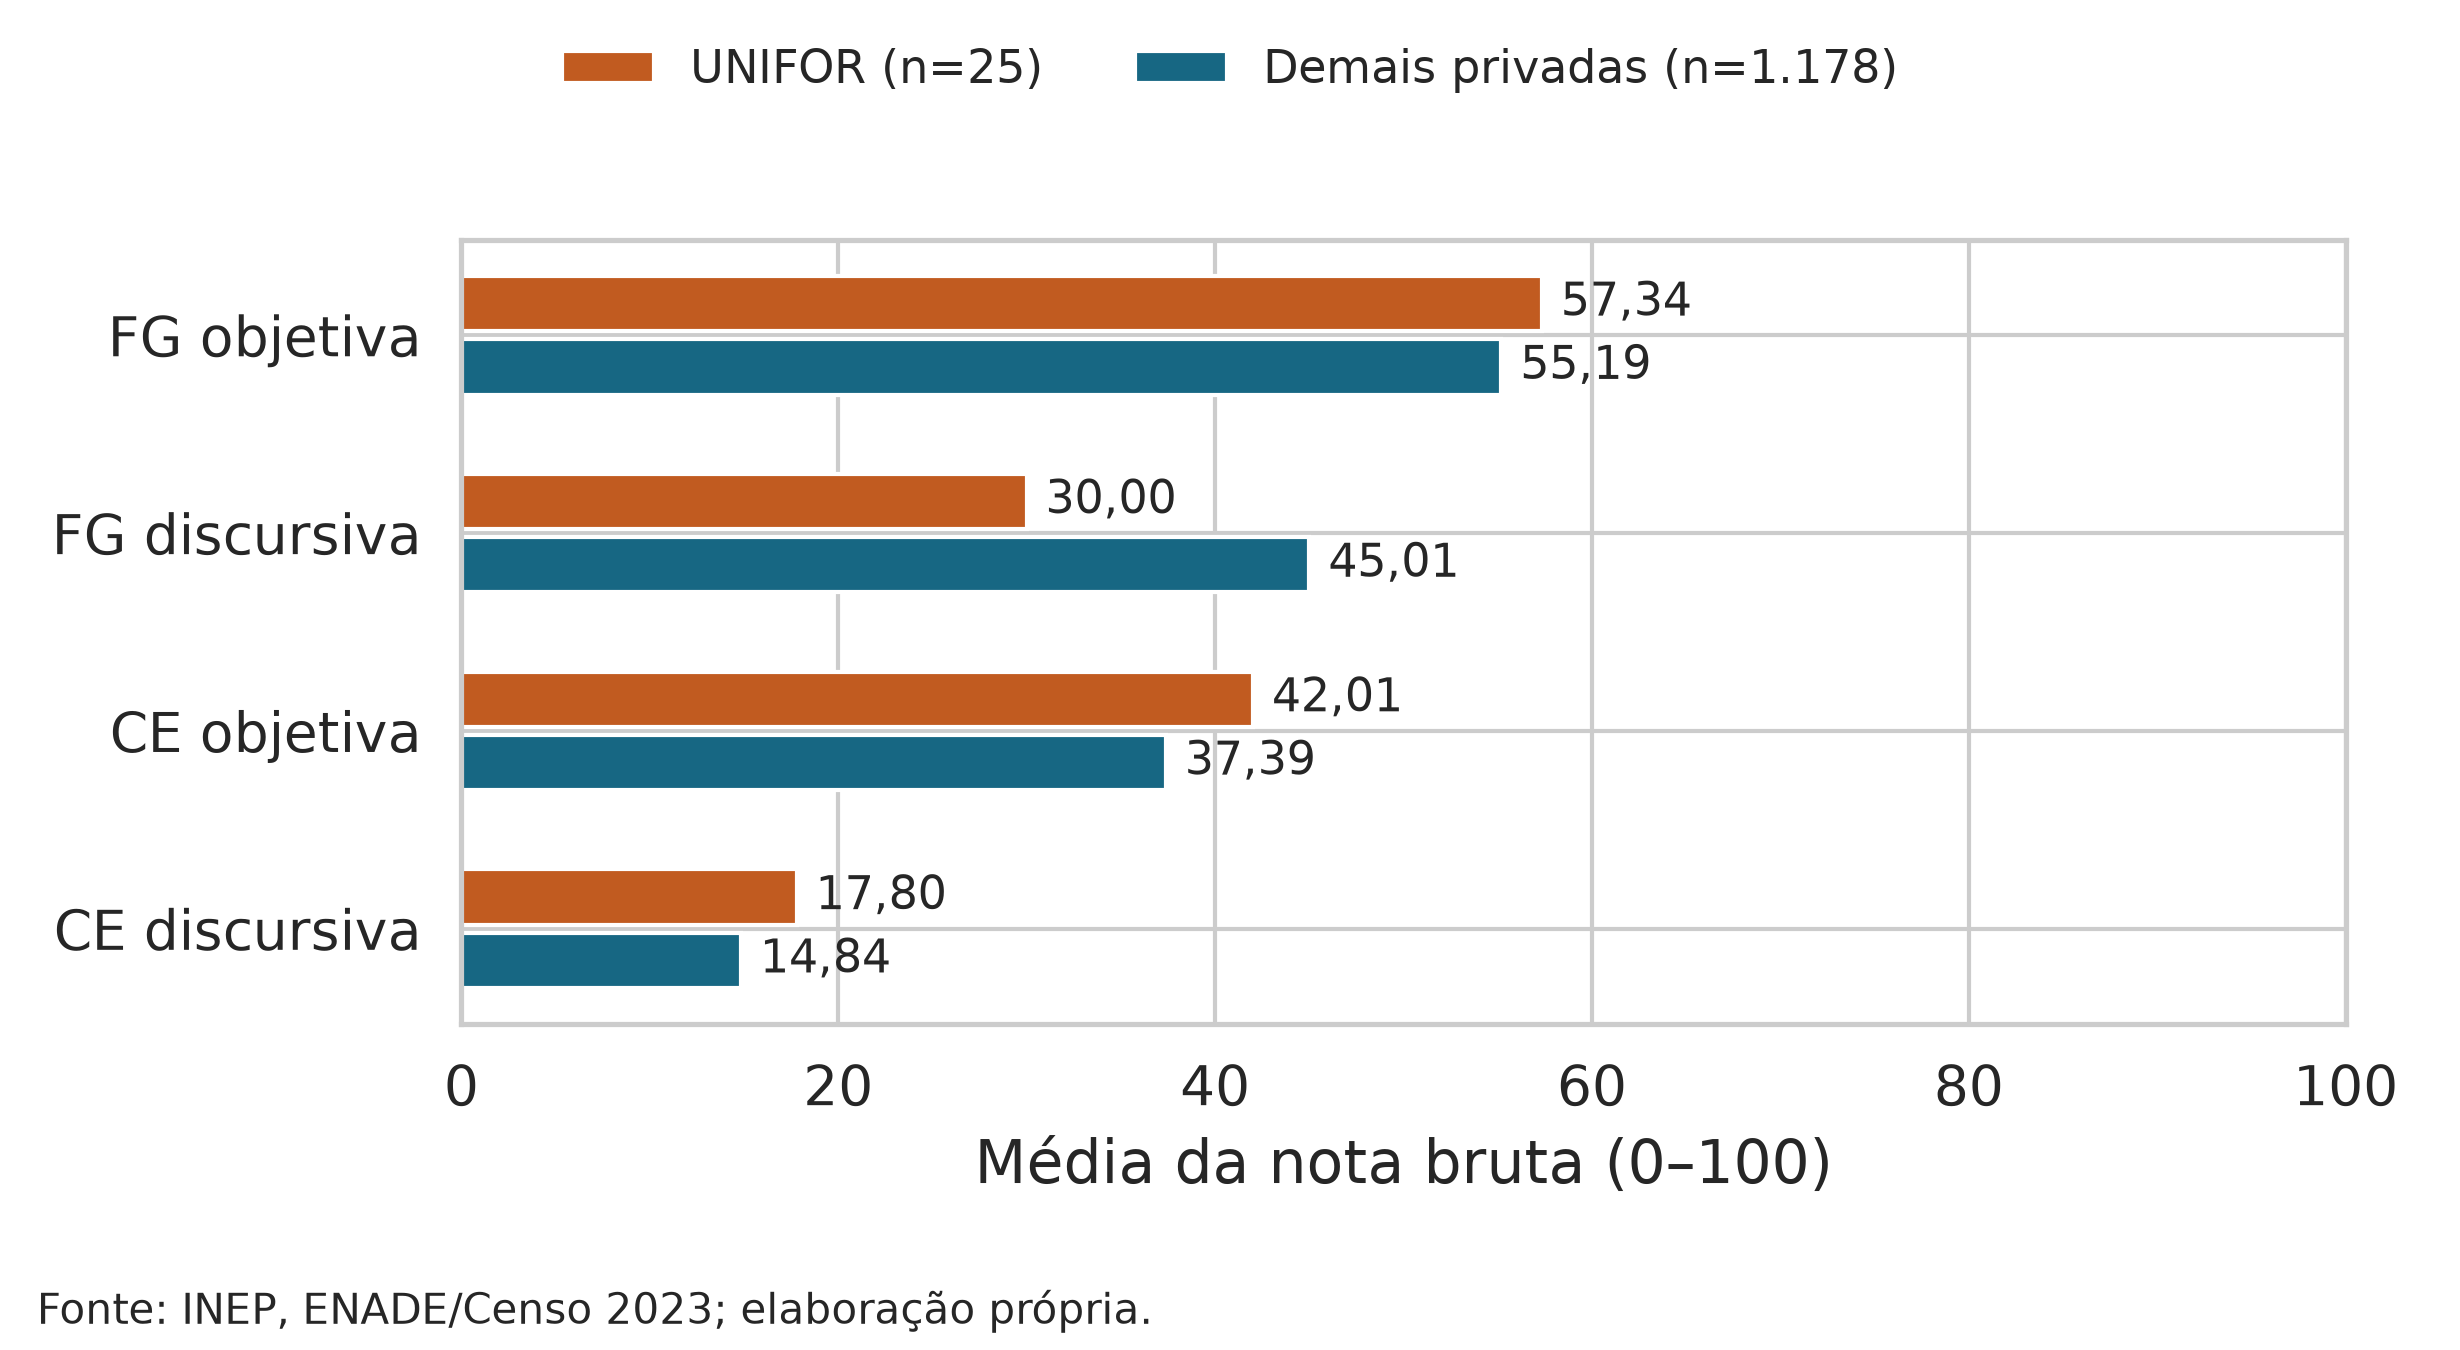

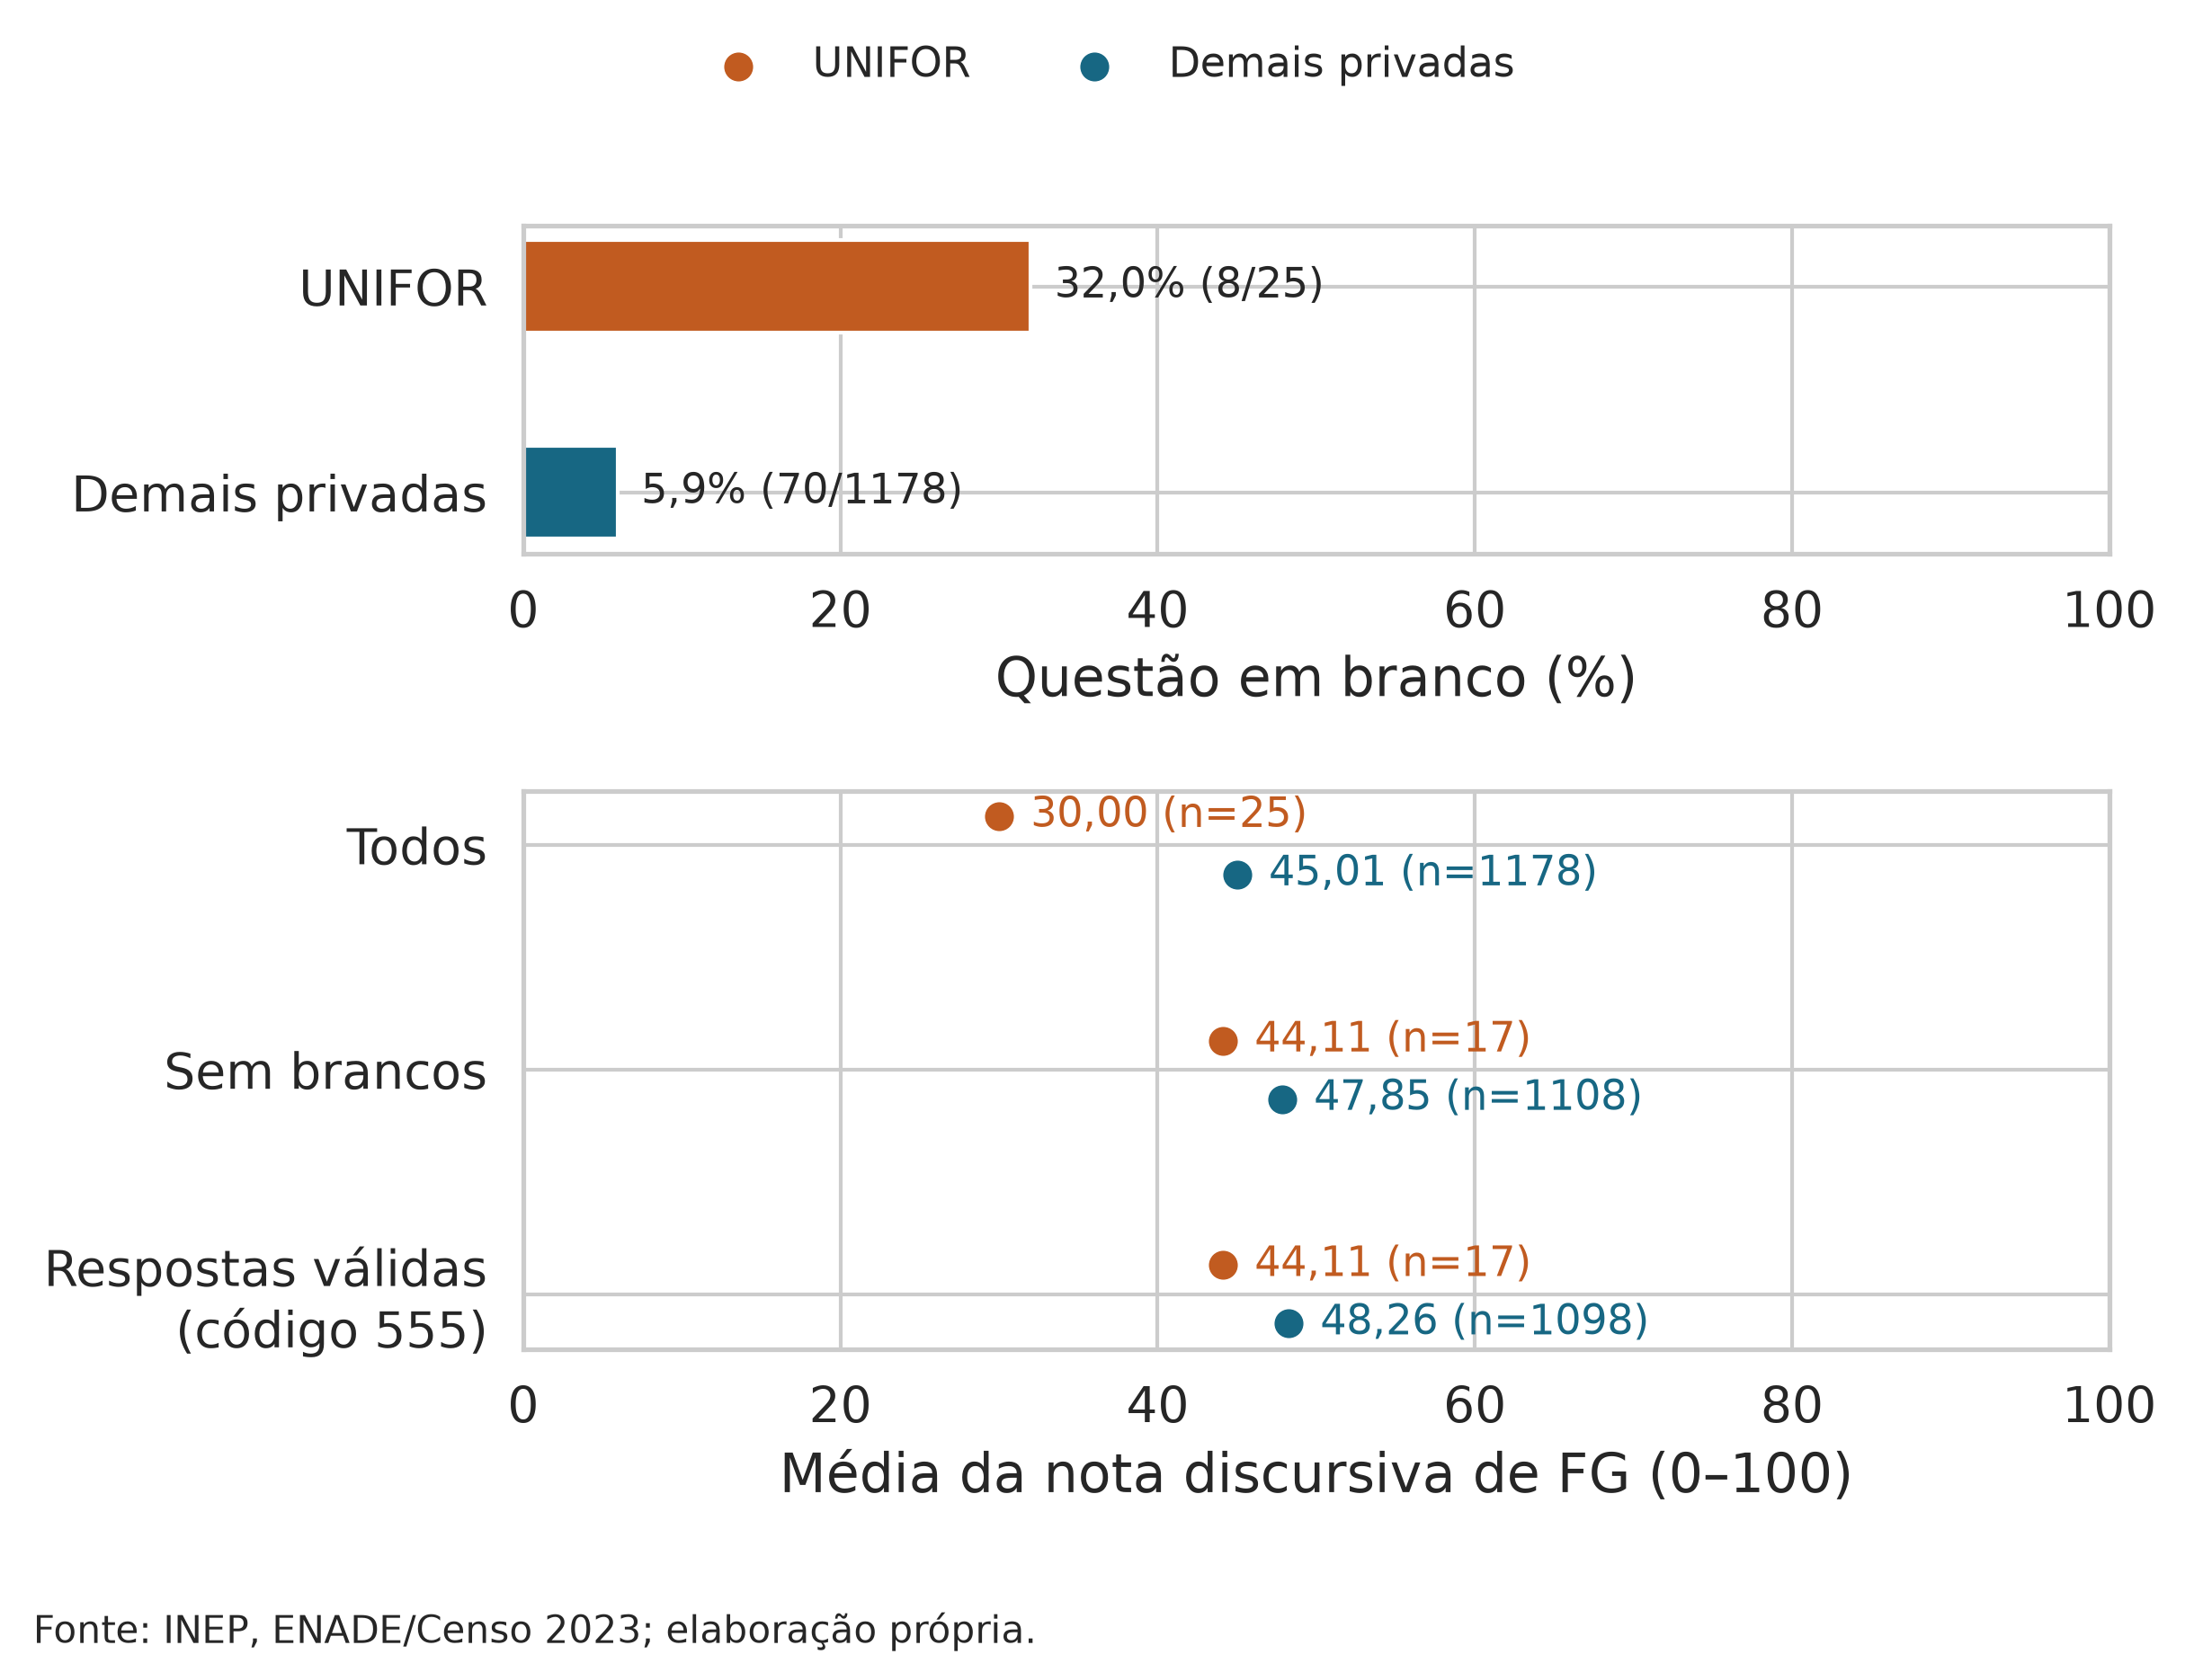

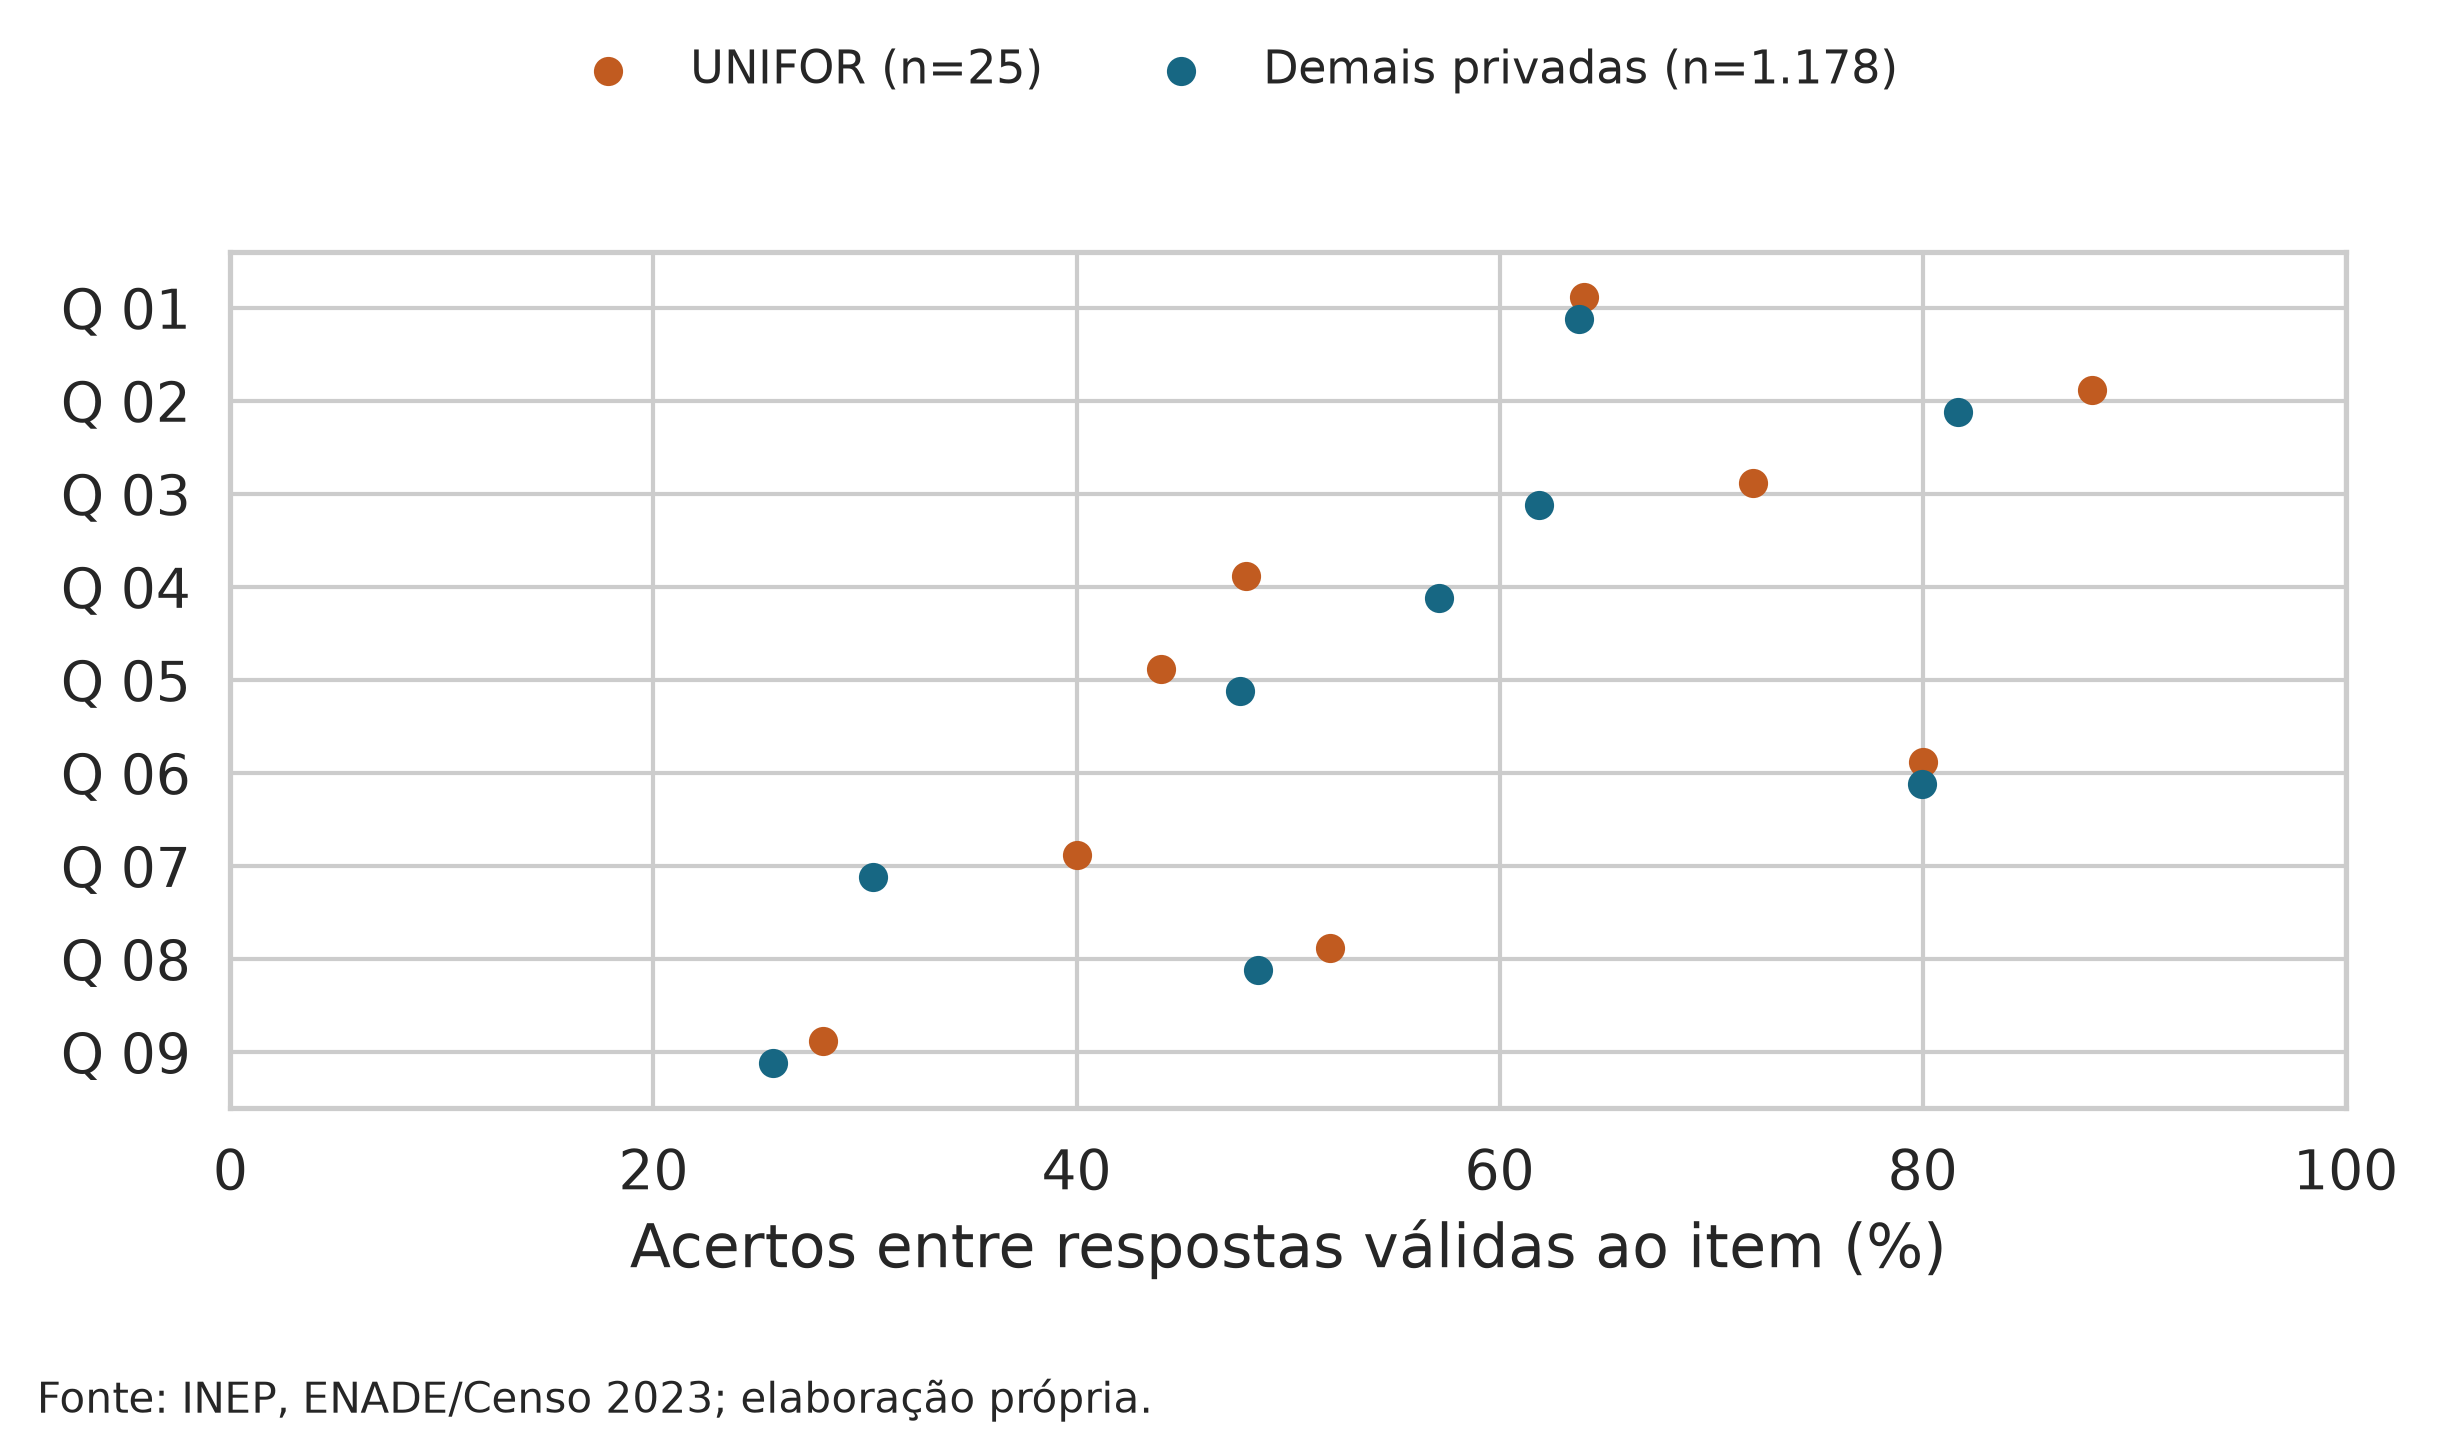

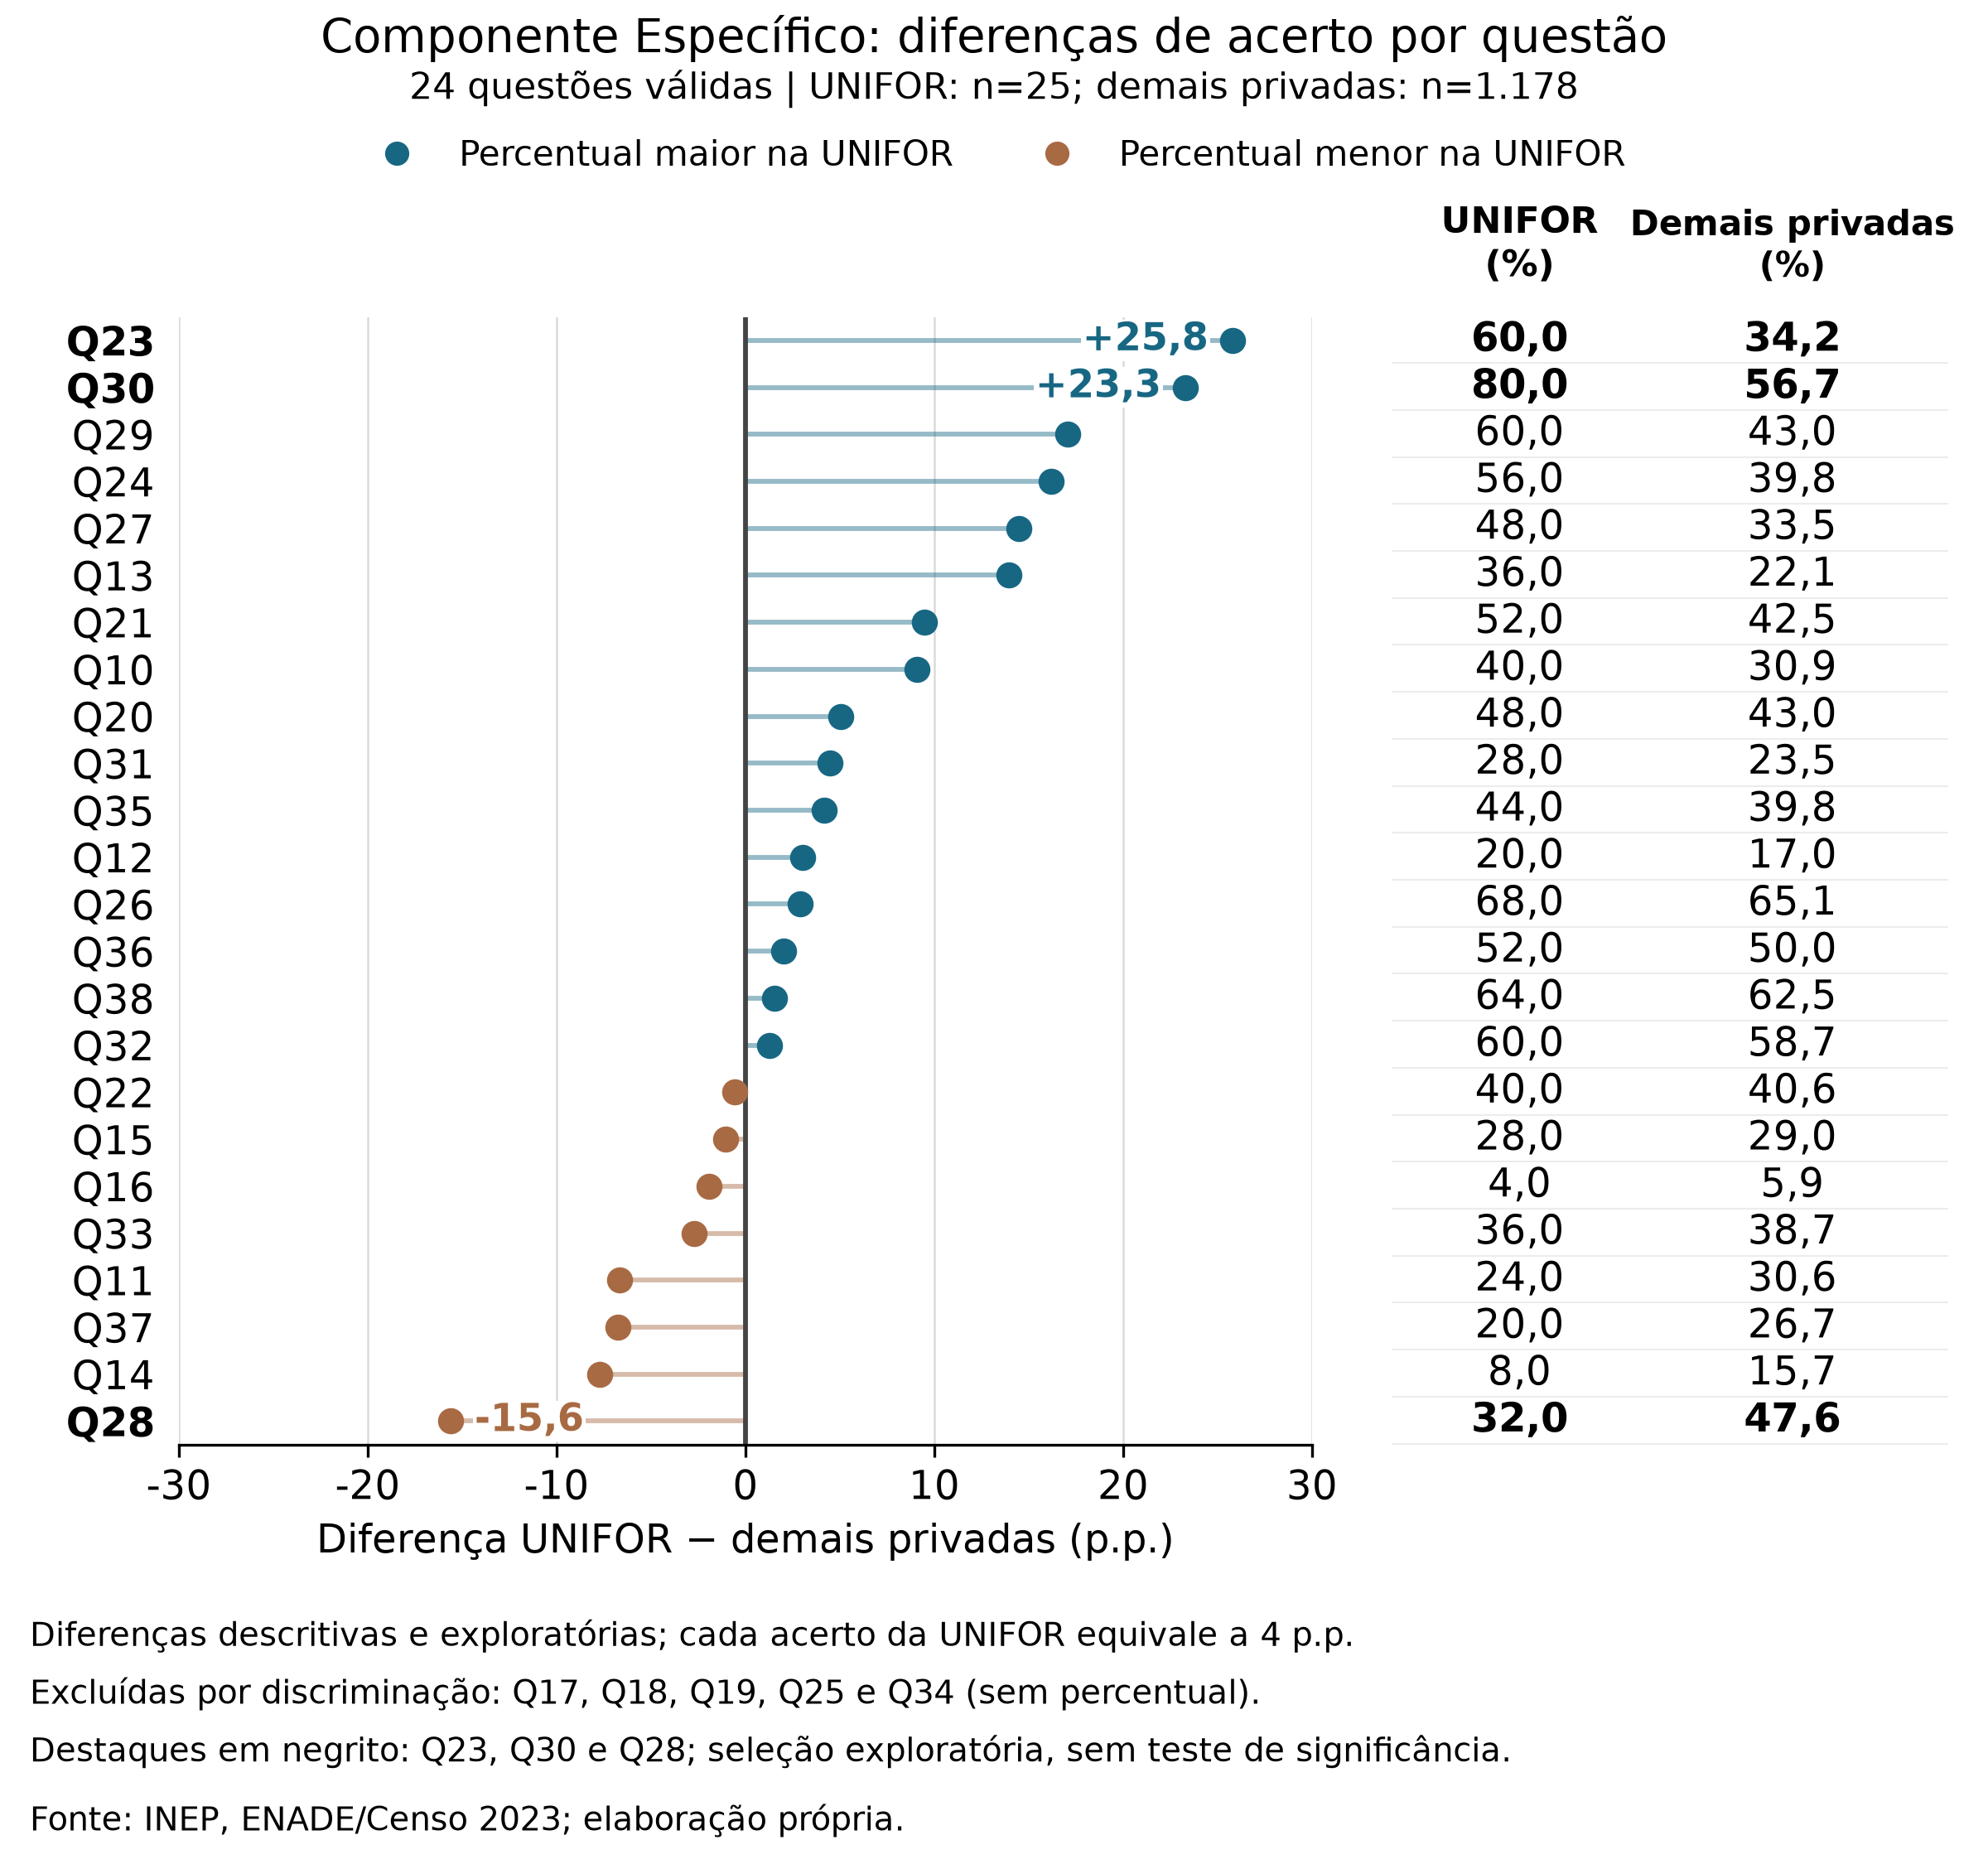

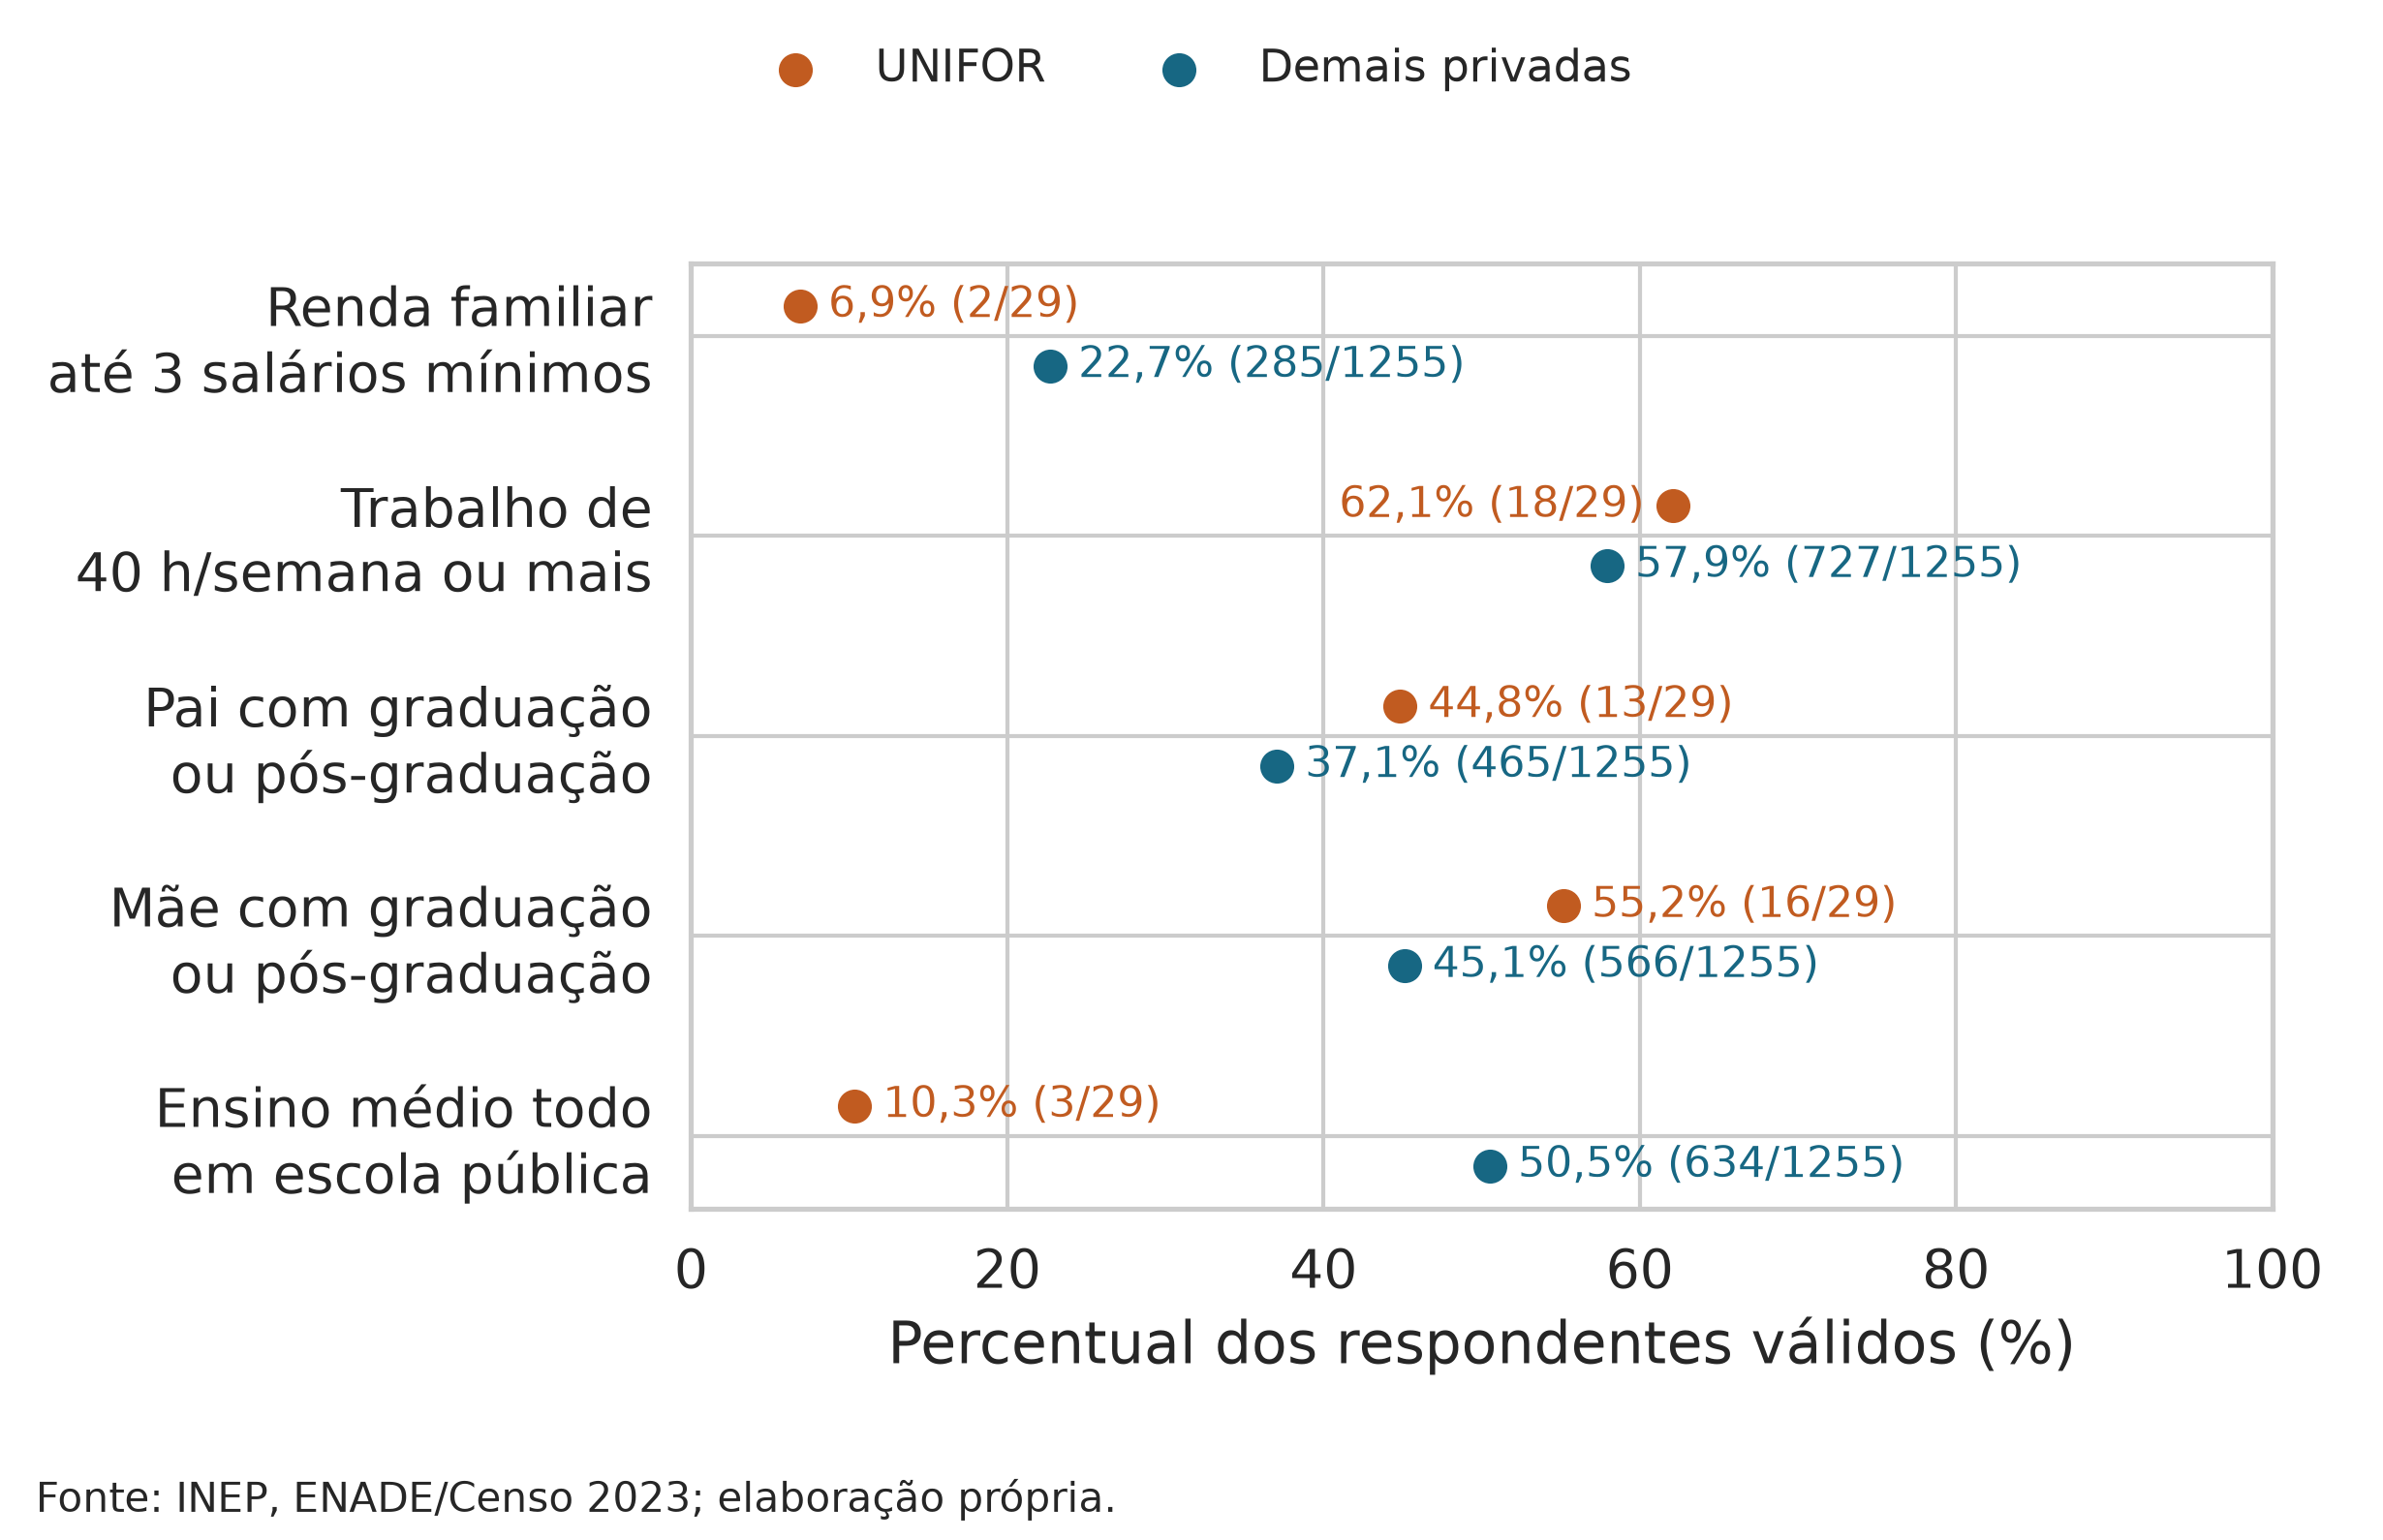

In [7]:
for nome in validacao['graficos']:
    if nome.endswith('.png'):
        display(Image(filename=str(ROOT/'resultados/graficos'/nome)))

## Validação e entrega
A revisão reproduz o modelo `DOCUMENT/modelos/main.tex` em `DOCUMENT/main.tex`. Os testes e a auditoria independente constam dos JSONs abaixo. A paginação é pendente: não há compilador local nem PDF completo. Não houve uso de serviço externo ou importação automática. O bônus de 2021 continua pendente por ausência de dados; consulte o notebook 06.

In [8]:
for nome in ['validacao_independente_aprofundamento_2023.json','validacao_fg_discursiva_2023.json']:
    display(json.loads((T/nome).read_text(encoding='utf-8')))
print(validacao['bonus_2021'])

{'status': 'aprovado',
 'origem': 'releitura ZIP oficial via csv, Counter e statistics',
 'verificacoes': {'denominadores': 6,
  'estatisticas': 210,
  'correlacoes_individuais': 5,
  'itens': 925,
  'proporcoes_marginais': 12390,
  'indicadores': 50,
  'ecologicas': 10},
 'total_verificacoes': 13596,
 'hashes_entradas_saidas_brutos_conferidos': True,
 'sem_pareamento_individual_entre_arquivos': True}

{'status': 'aprovado',
 'conferencias_independentes': 50,
 'definicoes': {'brancos': 'TP_SFG_D1=333',
  'sem_brancos': 'TP_SFG_D1!=333',
  'respostas_validas': 'TP_SFG_D1=555; exclui também 335 e 336'},
 'fonte': 'Releitura do arq3 oficial, csv/statistics; sem vínculos entre arquivos',
 'ressalva_336': 'Há três notas publicadas positivas em código 336 (9, 11 e 14). Valores preservados, sem recodificação.',
 'sha256_tabela': 'c81d2aa3a38b2cf58372c569ba888388f227ec9ad9a8e19603c24bafe25cd43a'}

{'arquivos_locais': {'enade_2021': [], 'censo_2021': []}, 'status': 'pendente_sem_microdados'}


## TASK 14 — consulta da versão anterior do gráfico CE

A Figura 5 passou a mostrar as 24 diferenças em pontos percentuais, ordenadas, com percentuais absolutos nas colunas. Q23 (+25,79 p.p.), Q30 (+23,29 p.p.) e Q28 (−15,62 p.p.) são destaques exploratórios, sem novos testes estatísticos. Os denominadores permanecem 25 e 1.178; um acerto da UNIFOR equivale a 4 p.p.

Abaixo permanece a imagem anterior, com percentuais absolutos na ordem Q10–Q38 e cinco linhas de exclusão, preservada sem alteração para consulta. Ela não é a Figura 5 atual.

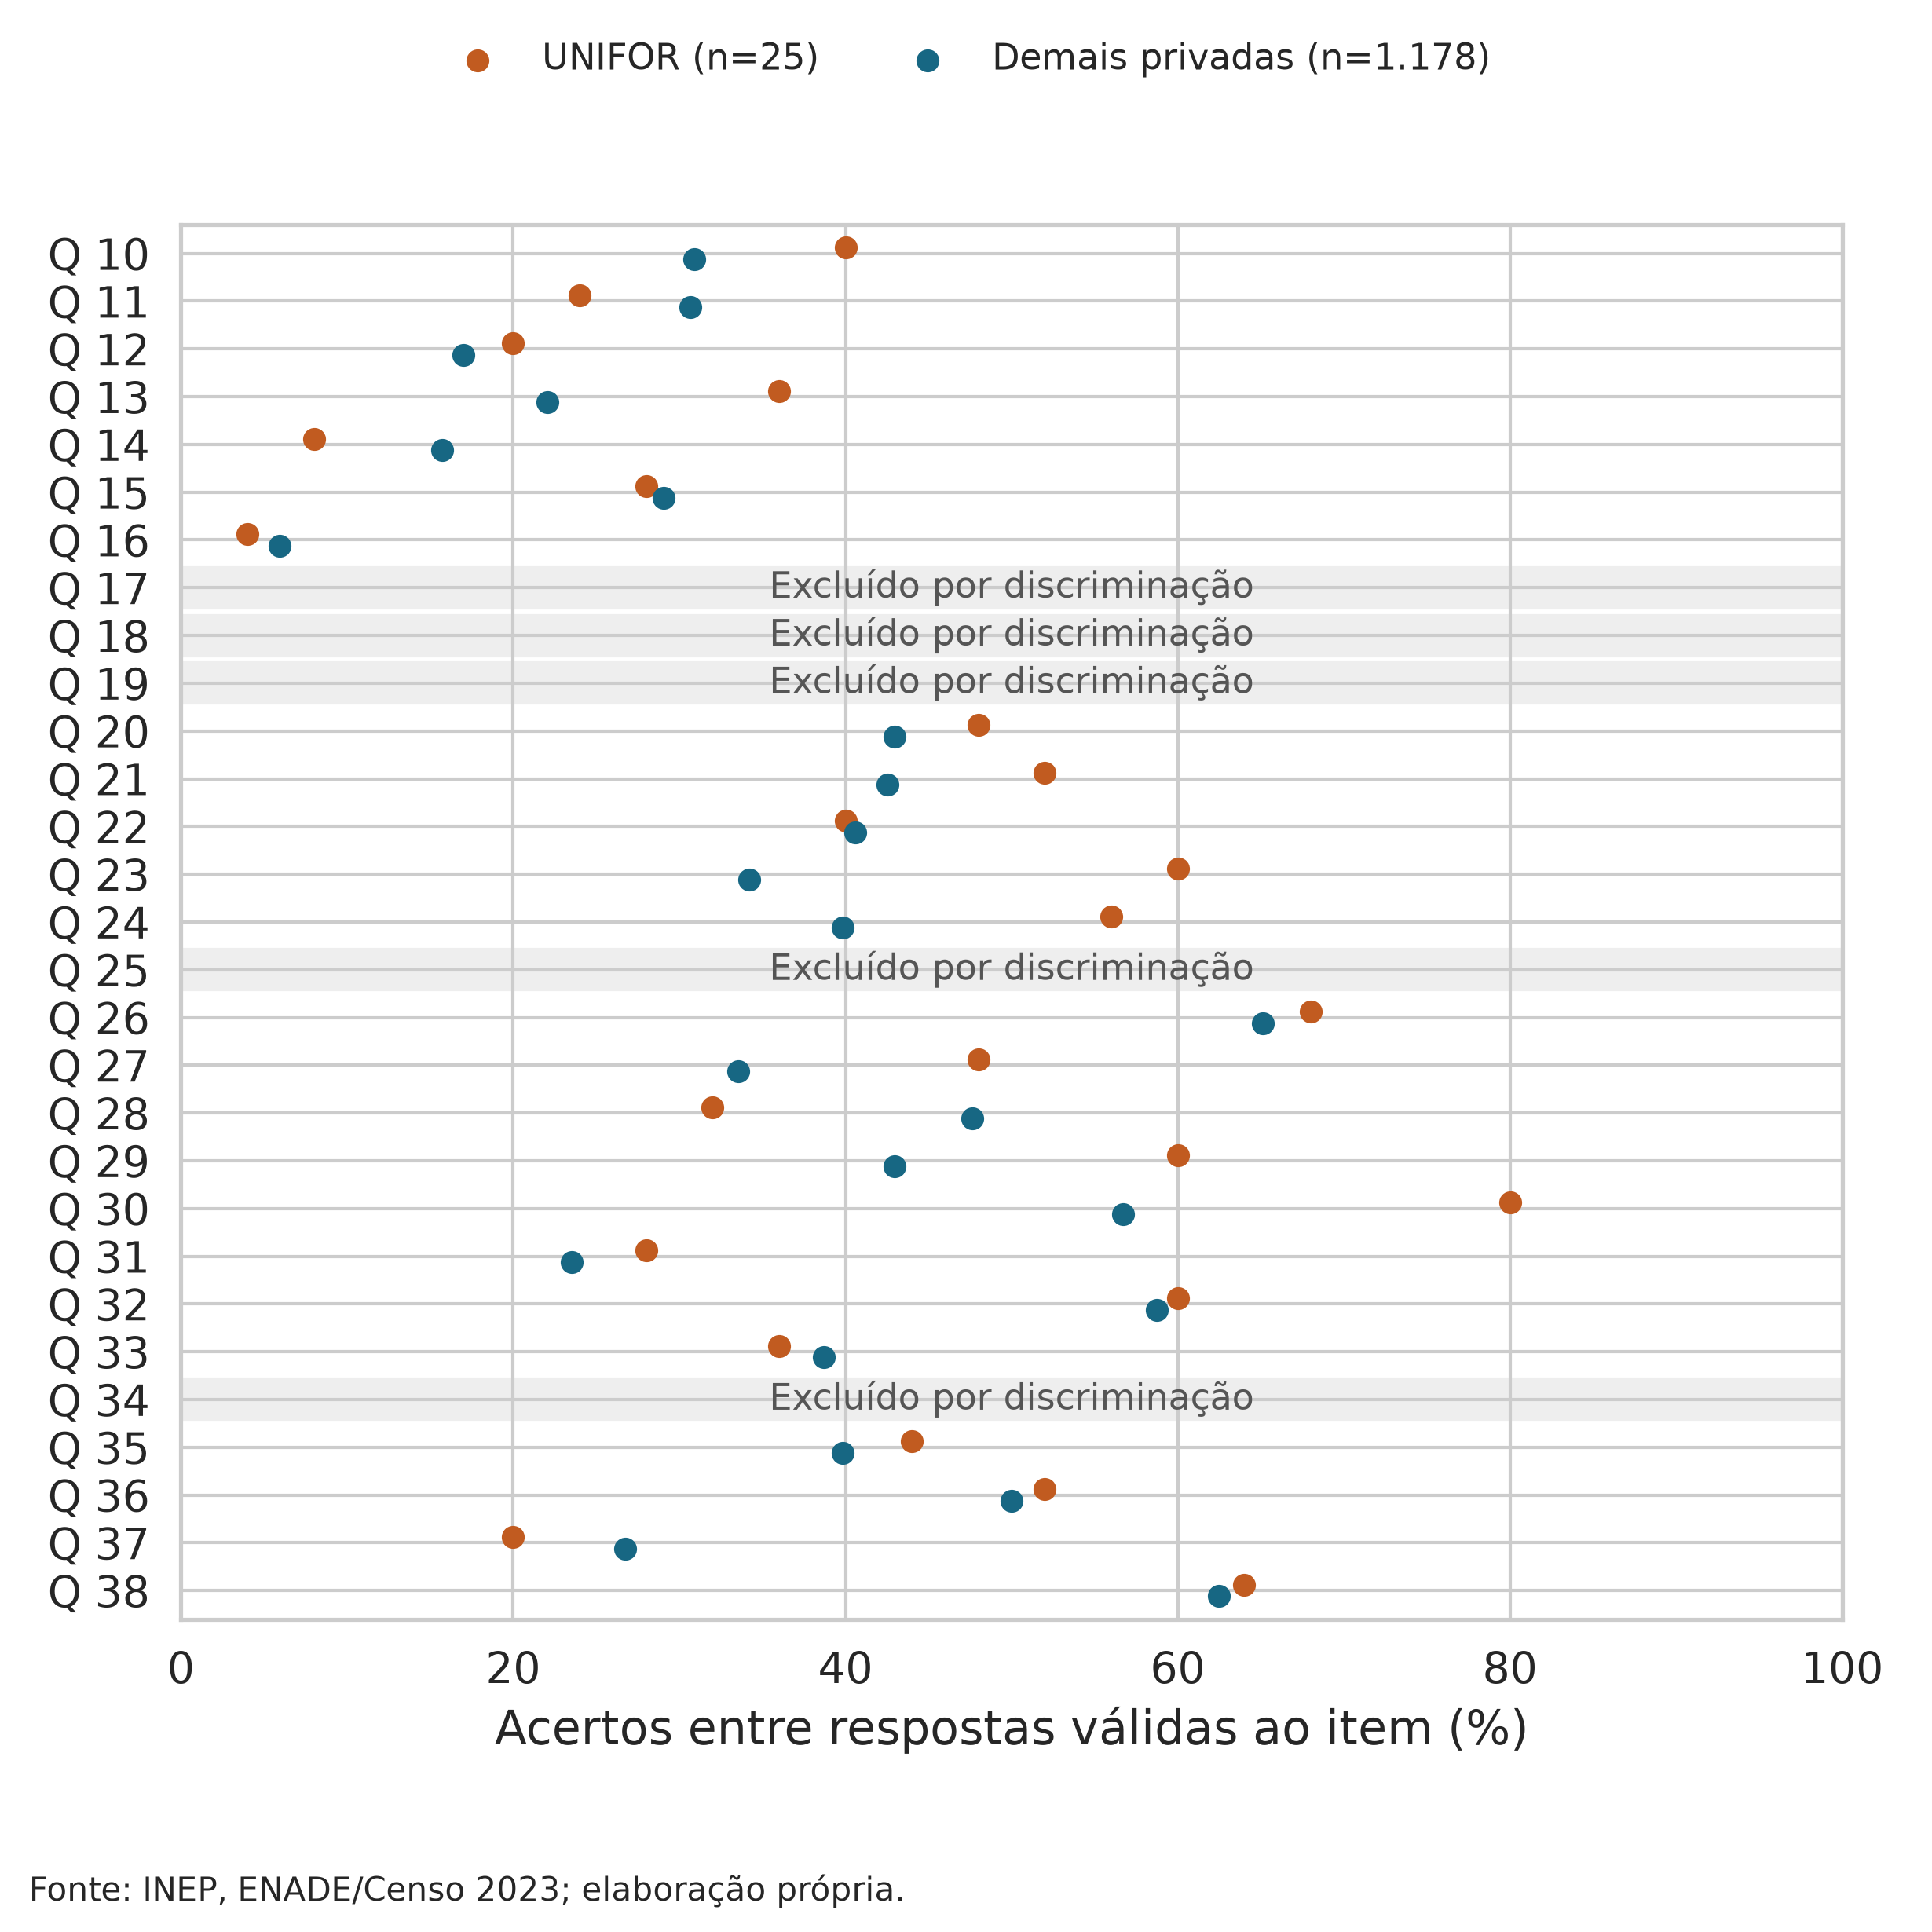

In [9]:
display(Image(filename=str(ROOT/'resultados/graficos/itens_ce_absolutos_2023.png')))